AUTHOR: MD MAINUL ISLAM

In [1]:
import pandas as pd
import numpy as np
import os
import os
import csv
import matplotlib.pyplot as plt

In [2]:
DATA_PATH = r"./home-credit-default-risk"
files = os.listdir(DATA_PATH)

files

['application_test.csv',
 'application_train.csv',
 'bureau.csv',
 'bureau_balance.csv',
 'credit_card_balance.csv',
 'HomeCredit_columns_description.csv',
 'installments_payments.csv',
 'POS_CASH_balance.csv',
 'previous_application.csv',
 'sample_submission.csv']

In [3]:
files=['application_test.csv',
 'application_train.csv',
 'bureau.csv',
 'bureau_balance.csv',
 'credit_card_balance.csv',
 'HomeCredit_columns_description.csv',
 'installments_payments.csv',
 'POS_CASH_balance.csv',
 'previous_application.csv',
 'sample_submission.csv']



for file in files:
    path = os.path.join(DATA_PATH, file)

    with open(path, "rb") as f:
        rows = sum(1 for _ in f) - 1   # subtract header

    # Get number of columns from the first line
    with open(path, "rb") as f:
        header = next(f)

    columns = len(next(csv.reader([header.decode("latin1")]))) 

    print(f"{file:35} → {rows:,} rows × {columns} columns")

application_test.csv                → 48,744 rows × 121 columns
application_train.csv               → 307,511 rows × 122 columns
bureau.csv                          → 1,716,428 rows × 17 columns
bureau_balance.csv                  → 27,299,925 rows × 3 columns
credit_card_balance.csv             → 3,840,312 rows × 23 columns
HomeCredit_columns_description.csv  → 219 rows × 5 columns
installments_payments.csv           → 13,605,401 rows × 8 columns
POS_CASH_balance.csv                → 10,001,358 rows × 8 columns
previous_application.csv            → 1,670,214 rows × 37 columns
sample_submission.csv               → 48,744 rows × 2 columns


In [4]:
application_train = pd.read_csv(
    os.path.join(DATA_PATH, "application_train.csv")
)

print(application_train.shape)

(307511, 122)


In [5]:
application_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
for i, col in enumerate(application_train.columns, start=1):
    print(f"{i:3}. {col}")

  1. SK_ID_CURR
  2. TARGET
  3. NAME_CONTRACT_TYPE
  4. CODE_GENDER
  5. FLAG_OWN_CAR
  6. FLAG_OWN_REALTY
  7. CNT_CHILDREN
  8. AMT_INCOME_TOTAL
  9. AMT_CREDIT
 10. AMT_ANNUITY
 11. AMT_GOODS_PRICE
 12. NAME_TYPE_SUITE
 13. NAME_INCOME_TYPE
 14. NAME_EDUCATION_TYPE
 15. NAME_FAMILY_STATUS
 16. NAME_HOUSING_TYPE
 17. REGION_POPULATION_RELATIVE
 18. DAYS_BIRTH
 19. DAYS_EMPLOYED
 20. DAYS_REGISTRATION
 21. DAYS_ID_PUBLISH
 22. OWN_CAR_AGE
 23. FLAG_MOBIL
 24. FLAG_EMP_PHONE
 25. FLAG_WORK_PHONE
 26. FLAG_CONT_MOBILE
 27. FLAG_PHONE
 28. FLAG_EMAIL
 29. OCCUPATION_TYPE
 30. CNT_FAM_MEMBERS
 31. REGION_RATING_CLIENT
 32. REGION_RATING_CLIENT_W_CITY
 33. WEEKDAY_APPR_PROCESS_START
 34. HOUR_APPR_PROCESS_START
 35. REG_REGION_NOT_LIVE_REGION
 36. REG_REGION_NOT_WORK_REGION
 37. LIVE_REGION_NOT_WORK_REGION
 38. REG_CITY_NOT_LIVE_CITY
 39. REG_CITY_NOT_WORK_CITY
 40. LIVE_CITY_NOT_WORK_CITY
 41. ORGANIZATION_TYPE
 42. EXT_SOURCE_1
 43. EXT_SOURCE_2
 44. EXT_SOURCE_3
 45. APARTMENTS_AVG
 46

In [7]:
categorical_cols = application_train.select_dtypes(
    include=["object"]
).columns

numerical_cols = application_train.select_dtypes(
    exclude=["object"]
).columns

print("Categorical columns:", len(categorical_cols))
print("Numerical columns:", len(numerical_cols))

print("\nCategorical:")
for col in categorical_cols:
    print(col)

print("\nNumerical:")
for col in numerical_cols:
    print(col)

Categorical columns: 16
Numerical columns: 106

Categorical:
NAME_CONTRACT_TYPE
CODE_GENDER
FLAG_OWN_CAR
FLAG_OWN_REALTY
NAME_TYPE_SUITE
NAME_INCOME_TYPE
NAME_EDUCATION_TYPE
NAME_FAMILY_STATUS
NAME_HOUSING_TYPE
OCCUPATION_TYPE
WEEKDAY_APPR_PROCESS_START
ORGANIZATION_TYPE
FONDKAPREMONT_MODE
HOUSETYPE_MODE
WALLSMATERIAL_MODE
EMERGENCYSTATE_MODE

Numerical:
SK_ID_CURR
TARGET
CNT_CHILDREN
AMT_INCOME_TOTAL
AMT_CREDIT
AMT_ANNUITY
AMT_GOODS_PRICE
REGION_POPULATION_RELATIVE
DAYS_BIRTH
DAYS_EMPLOYED
DAYS_REGISTRATION
DAYS_ID_PUBLISH
OWN_CAR_AGE
FLAG_MOBIL
FLAG_EMP_PHONE
FLAG_WORK_PHONE
FLAG_CONT_MOBILE
FLAG_PHONE
FLAG_EMAIL
CNT_FAM_MEMBERS
REGION_RATING_CLIENT
REGION_RATING_CLIENT_W_CITY
HOUR_APPR_PROCESS_START
REG_REGION_NOT_LIVE_REGION
REG_REGION_NOT_WORK_REGION
LIVE_REGION_NOT_WORK_REGION
REG_CITY_NOT_LIVE_CITY
REG_CITY_NOT_WORK_CITY
LIVE_CITY_NOT_WORK_CITY
EXT_SOURCE_1
EXT_SOURCE_2
EXT_SOURCE_3
APARTMENTS_AVG
BASEMENTAREA_AVG
YEARS_BEGINEXPLUATATION_AVG
YEARS_BUILD_AVG
COMMONAREA_AVG
ELEVAT

In [8]:
print(application_train["TARGET"].value_counts())

print("\nPercentage:")
print(application_train["TARGET"].value_counts(normalize=True).mul(100).round(2))

TARGET
0    282686
1     24825
Name: count, dtype: int64

Percentage:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64


In [9]:
for col in categorical_cols:
    print(f"{col:35} → {application_train[col].nunique()} unique values")

NAME_CONTRACT_TYPE                  → 2 unique values
CODE_GENDER                         → 3 unique values
FLAG_OWN_CAR                        → 2 unique values
FLAG_OWN_REALTY                     → 2 unique values
NAME_TYPE_SUITE                     → 7 unique values
NAME_INCOME_TYPE                    → 8 unique values
NAME_EDUCATION_TYPE                 → 5 unique values
NAME_FAMILY_STATUS                  → 6 unique values
NAME_HOUSING_TYPE                   → 6 unique values
OCCUPATION_TYPE                     → 18 unique values
WEEKDAY_APPR_PROCESS_START          → 7 unique values
ORGANIZATION_TYPE                   → 58 unique values
FONDKAPREMONT_MODE                  → 4 unique values
HOUSETYPE_MODE                      → 3 unique values
WALLSMATERIAL_MODE                  → 7 unique values
EMERGENCYSTATE_MODE                 → 2 unique values


In [10]:
missing = application_train.isnull().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing_percentage = (missing / len(application_train) * 100).round(2)

missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_percentage
})

missing_summary

,Missing Count,Missing %
COMMONAREA_MEDI,214865,69.87
COMMONAREA_MODE,214865,69.87
COMMONAREA_AVG,214865,69.87
NONLIVINGAPARTMENTS_MODE,213514,69.43
NONLIVINGAPARTMENTS_MEDI,213514,69.43
...,...,...
EXT_SOURCE_2,660,0.21
AMT_GOODS_PRICE,278,0.09
AMT_ANNUITY,12,0.00
CNT_FAM_MEMBERS,2,0.00


In [11]:
missing_percentage = (application_train.isnull().sum() / len(application_train) * 100)

high_missing = missing_percentage[missing_percentage >= 50].sort_values(ascending=False)

high_missing

COMMONAREA_AVG              69.872297
COMMONAREA_MEDI             69.872297
COMMONAREA_MODE             69.872297
NONLIVINGAPARTMENTS_AVG     69.432963
NONLIVINGAPARTMENTS_MODE    69.432963
NONLIVINGAPARTMENTS_MEDI    69.432963
FONDKAPREMONT_MODE          68.386172
LIVINGAPARTMENTS_AVG        68.354953
LIVINGAPARTMENTS_MODE       68.354953
LIVINGAPARTMENTS_MEDI       68.354953
FLOORSMIN_MODE              67.848630
FLOORSMIN_MEDI              67.848630
FLOORSMIN_AVG               67.848630
YEARS_BUILD_MODE            66.497784
YEARS_BUILD_MEDI            66.497784
YEARS_BUILD_AVG             66.497784
OWN_CAR_AGE                 65.990810
LANDAREA_MODE               59.376738
LANDAREA_MEDI               59.376738
LANDAREA_AVG                59.376738
BASEMENTAREA_MODE           58.515956
BASEMENTAREA_AVG            58.515956
BASEMENTAREA_MEDI           58.515956
EXT_SOURCE_1                56.381073
NONLIVINGAREA_MEDI          55.179164
NONLIVINGAREA_AVG           55.179164
NONLIVINGARE

In [12]:
application_train.groupby(application_train['EXT_SOURCE_1'].isna())['TARGET'].mean()

EXT_SOURCE_1
False    0.074955
True     0.085195
Name: TARGET, dtype: float64

In [13]:
application_train.groupby(
    application_train['COMMONAREA_AVG'].isna()
)['TARGET'].mean()

COMMONAREA_AVG
False    0.069102
True     0.085742
Name: TARGET, dtype: float64

In [14]:
application_train.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.999706,402490.776996,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110757,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204685,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916002,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.794056,0.0,0.0,0.0,0.0,261.0


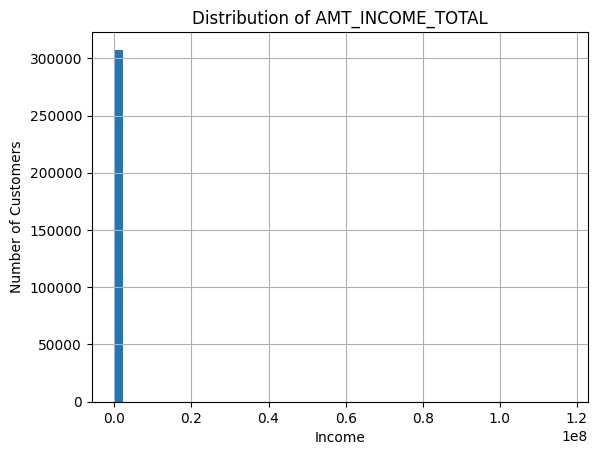

In [15]:

application_train['AMT_INCOME_TOTAL'].hist(bins=50)

plt.xlabel('Income')
plt.ylabel('Number of Customers')
plt.title('Distribution of AMT_INCOME_TOTAL')
plt.show()

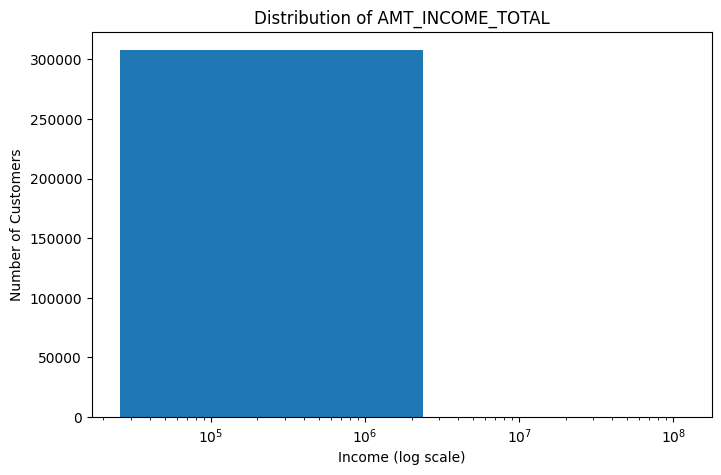

In [16]:
plt.figure(figsize=(8, 5))

plt.hist(application_train['AMT_INCOME_TOTAL'], bins=50)

plt.xscale('log')
plt.xlabel('Income (log scale)')
plt.ylabel('Number of Customers')
plt.title('Distribution of AMT_INCOME_TOTAL')

plt.show()

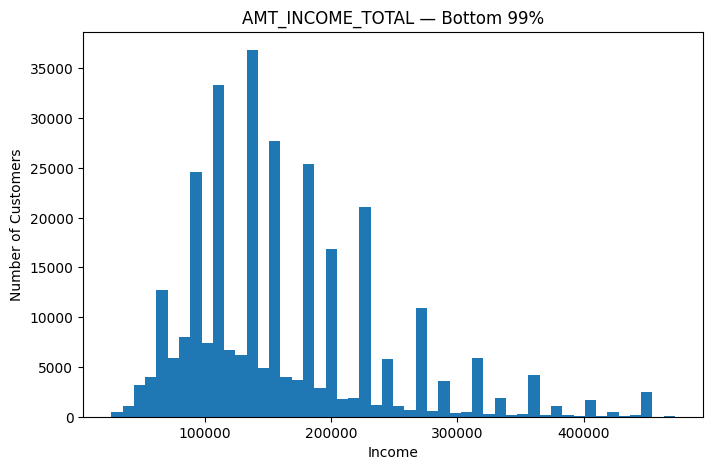

In [17]:
income_99 = application_train['AMT_INCOME_TOTAL'].quantile(0.99)

plt.figure(figsize=(8, 5))
plt.hist(
    application_train[application_train['AMT_INCOME_TOTAL'] <= income_99]['AMT_INCOME_TOTAL'],
    bins=50
)

plt.xlabel('Income')
plt.ylabel('Number of Customers')
plt.title('AMT_INCOME_TOTAL — Bottom 99%')
plt.show()

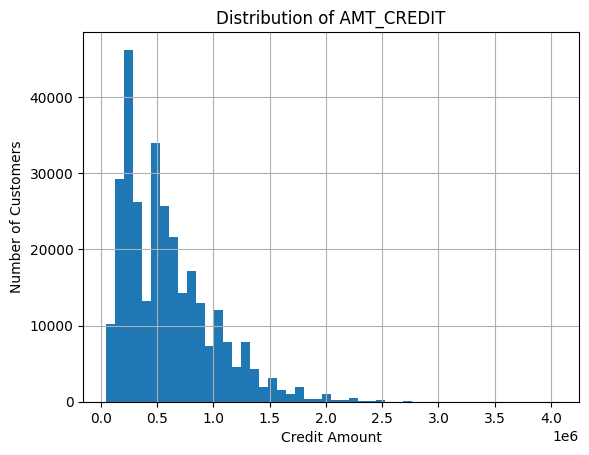

In [18]:
application_train['AMT_CREDIT'].hist(bins=50)

plt.xlabel('Credit Amount')
plt.ylabel('Number of Customers')
plt.title('Distribution of AMT_CREDIT')
plt.show()

In [19]:
application_train['INCOME_GROUP'] = pd.qcut(
    application_train['AMT_INCOME_TOTAL'],
    q=5,
    duplicates='drop'
)

application_train.groupby('INCOME_GROUP', observed=True)['TARGET'].mean()

INCOME_GROUP
(25649.999, 99000.0]       0.082062
(99000.0, 135000.0]        0.085883
(135000.0, 162000.0]       0.086847
(162000.0, 225000.0]       0.080569
(225000.0, 117000000.0]    0.065198
Name: TARGET, dtype: float64

What does this suggest?

There is a general downward relationship at higher income levels.

The highest-income group has a default rate of 6.52%, compared with about 8.6% for the middle-income groups.

So a possible business finding is:

Higher-income applicants appear to have lower repayment difficulty rates, suggesting income may be an important indicator of repayment capacity.

But notice something interesting:

The relationship isn't perfectly linear.

Low       → 8.21%
Low-mid   → 8.59%
Middle    → 8.68%  ← highest
High-mid  → 8.06%
High      → 6.52%  ← lowest

That's exactly why EDA is useful before modeling. A model can potentially capture these nonlinear relationships.

One caution

Don't conclude yet that:

"High income causes lower default."

This is an association, not causation. Other variables—loan size, age, employment, education, etc.—may explain part of the difference.

In [20]:
application_train['CREDIT_GROUP'] = pd.qcut(
    application_train['AMT_CREDIT'],
    q=5,
    duplicates='drop'
)

application_train.groupby('CREDIT_GROUP', observed=True)['TARGET'].mean()

CREDIT_GROUP
(44999.999, 254700.0]    0.072376
(254700.0, 432000.0]     0.091724
(432000.0, 604152.0]     0.100549
(604152.0, 900000.0]     0.078549
(900000.0, 4050000.0]    0.060752
Name: TARGET, dtype: float64

What does this tell us?

Interestingly, the relationship is not simply "higher loan → higher default."

The middle credit group has the highest default rate: 10.05%.
The highest-credit group has the lowest rate: 6.08%.
Applicants with the largest loans may also have stronger financial profiles, allowing them to qualify for larger credit amounts.
This suggests that credit amount alone is not enough to assess risk. Income, employment, previous credit behavior, and repayment history likely interact with it.
Important business insight

A particularly interesting finding for your project is:

Medium-sized loans appear riskier than both the smallest and largest loans.

But don't conclude that large loans cause lower default. This is an association, and later ML models can capture the interaction between credit amount and other applicant characteristics.

In [21]:
application_train['CREDIT_INCOME_RATIO'] = (
    application_train['AMT_CREDIT'] /
    application_train['AMT_INCOME_TOTAL']
)

In [22]:
application_train.groupby(
    pd.qcut(application_train['CREDIT_INCOME_RATIO'], 5)
)['TARGET'].mean()

C:\Users\USERAS\AppData\Local\Temp\ipykernel_17812\2448545733.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  application_train.groupby(


CREDIT_INCOME_RATIO
(0.00381, 1.818]    0.073352
(1.818, 2.764]      0.085672
(2.764, 3.906]      0.089253
(3.906, 5.769]      0.082839
(5.769, 84.737]     0.072538
Name: TARGET, dtype: float64

What we can say

There's a non-linear relationship:

Lowest ratio → 7.34%
Risk rises toward the middle → 8.93%
Then falls again → 7.25% at the highest ratio.

So surprisingly, applicants with the very highest credit-to-income ratios aren't the highest-risk group.

This reinforces an important point for our project:

Financial risk cannot be explained reliably by one variable. Relationships between variables matter.

For example, someone with a large loan may also have high income, strong employment history, or previous successful loans.

In [23]:
application_train.groupby('NAME_INCOME_TYPE')['TARGET'].agg(
    ['count', 'mean']
).sort_values('mean', ascending=False)

,count,mean
NAME_INCOME_TYPE,,
Maternity leave,5,0.400000
Unemployed,22,0.363636
Working,158774,0.095885
Commercial associate,71617,0.074843
State servant,21703,0.057550
Pensioner,55362,0.053864
Businessman,10,0.000000
Student,18,0.000000


What should we actually conclude?

Don't say:

"Maternity leave applicants have a 40% default rate."

That's misleading because there are only 5 applicants.

Instead, the reliable finding is:

Applicants classified as Working have a higher repayment-difficulty rate (9.59%) than Commercial Associates (7.48%), State Servants (5.76%), and Pensioners (5.39%).

The tiny categories should be marked as insufficient sample size rather than used as business conclusions.

🔎 Interesting observation

Notice something important:

Working applicants have almost twice the default rate of pensioners:

9.59% vs 5.39%

That doesn't mean being employed causes higher risk. Working applicants may differ substantially in age, income, loan amount, credit history, etc.

This is exactly why our eventual ML model needs multiple features simultaneously.

In [24]:
application_train['AGE_YEARS'] = (
    -application_train['DAYS_BIRTH'] / 365
)

In [25]:
application_train['AGE_GROUP'] = pd.cut(
    application_train['AGE_YEARS'],
    bins=[18, 25, 35, 45, 55, 65, 100]
)

In [26]:
application_train.groupby(
    'AGE_GROUP',
    observed=True
)['TARGET'].agg(['count', 'mean'])

,count,mean
AGE_GROUP,,
"(18, 25]",12159,0.123036
"(25, 35]",72302,0.106733
"(35, 45]",84274,0.084047
"(45, 55]",70077,0.070580
"(55, 65]",60596,0.054145
"(65, 100]",8103,0.037270


So the youngest group has a default rate more than 3× that of applicants aged 65+.

💼 Business insight

A strong finding for our presentation could be:

Younger applicants show substantially higher repayment difficulty, with default rates declining consistently as applicant age increases.

For Home Credit, this could support age-aware risk assessment, although age should not be used in isolation. Income, employment, credit history and loan characteristics can all interact with age.

One important observation

Unlike our credit-to-income ratio, this relationship is almost monotonic:

Age ↑ → repayment difficulty ↓

That makes AGE_YEARS potentially useful for our eventual ML models.

We've now identified several potentially meaningful predictors:

Income → higher-income applicants generally have lower risk.
Credit amount → middle credit groups have higher risk than both extremes.
Credit/income ratio → non-linear relationship.
Income type → risk varies substantially by employment/income category.
Age → strong decreasing relationship with repayment difficulty.

In [27]:
application_train.groupby('CODE_GENDER')['TARGET'].agg(
    ['count', 'mean']
).sort_values('mean', ascending=False)

,count,mean
CODE_GENDER,,
M,105059,0.101419
F,202448,0.069993
XNA,4,0.000000


Male applicants have a higher observed repayment-difficulty rate (10.14%) than female applicants (7.00%).

That's a difference of about 3.14 percentage points, and both major groups have very large sample sizes, so this isn't simply a tiny-sample artifact.

In [28]:
application_train.groupby('NAME_EDUCATION_TYPE')['TARGET'].agg(
    ['count', 'mean']
).sort_values('mean', ascending=False)

,count,mean
NAME_EDUCATION_TYPE,,
Lower secondary,3816,0.109277
Secondary / secondary special,218391,0.089399
Incomplete higher,10277,0.084850
Higher education,74863,0.053551
Academic degree,164,0.018293


The most notable comparison is:

Lower secondary: 10.93% → Higher education: 5.36%

That's roughly a 51% lower observed default rate.


Our EDA is beginning to tell a coherent story:

Higher risk

Younger applicants
Lower education
Working income category
Middle credit amounts
Middle credit-to-income ratios

Lower risk

Older applicants
Higher income
Higher education
State servants / pensioners
Very high credit amounts

Next step: bureau.csv

In [29]:
bureau = pd.read_csv(
    os.path.join(DATA_PATH, "bureau.csv")
)

print(bureau.shape)
print(bureau.head())

(1716428, 17)
   SK_ID_CURR  SK_ID_BUREAU CREDIT_ACTIVE CREDIT_CURRENCY  DAYS_CREDIT  \
0      215354       5714462        Closed      currency 1         -497   
1      215354       5714463        Active      currency 1         -208   
2      215354       5714464        Active      currency 1         -203   
3      215354       5714465        Active      currency 1         -203   
4      215354       5714466        Active      currency 1         -629   

   CREDIT_DAY_OVERDUE  DAYS_CREDIT_ENDDATE  DAYS_ENDDATE_FACT  \
0                   0               -153.0             -153.0   
1                   0               1075.0                NaN   
2                   0                528.0                NaN   
3                   0                  NaN                NaN   
4                   0               1197.0                NaN   

   AMT_CREDIT_MAX_OVERDUE  CNT_CREDIT_PROLONG  AMT_CREDIT_SUM  \
0                     NaN                   0         91323.0   
1                   

we'll eventually transform the bureau history into customer-level features such as:

number of previous credits
number of active credits
total previous credit
total outstanding debt
maximum overdue amount
number of overdue credits
average previous credit
previous credit types

In [30]:
bureau.isnull().mean().sort_values(ascending=False).head(10)

AMT_ANNUITY               0.714735
AMT_CREDIT_MAX_OVERDUE    0.655133
DAYS_ENDDATE_FACT         0.369170
AMT_CREDIT_SUM_LIMIT      0.344774
AMT_CREDIT_SUM_DEBT       0.150119
DAYS_CREDIT_ENDDATE       0.061496
AMT_CREDIT_SUM            0.000008
SK_ID_CURR                0.000000
SK_ID_BUREAU              0.000000
CREDIT_DAY_OVERDUE        0.000000
dtype: float64

In [31]:
columns_description = pd.read_csv(
    os.path.join(DATA_PATH, "HomeCredit_columns_description.csv"),
    encoding='latin1'
)

columns_description[
    columns_description['Table'] == 'bureau.csv'
][['Row', 'Description']]

,Row,Description
122,SK_ID_CURR,ID of loan in our sample - one loan in our sam...
123,SK_BUREAU_ID,Recoded ID of previous Credit Bureau credit re...
124,CREDIT_ACTIVE,Status of the Credit Bureau (CB) reported credits
125,CREDIT_CURRENCY,Recoded currency of the Credit Bureau credit
126,DAYS_CREDIT,How many days before current application did c...
127,CREDIT_DAY_OVERDUE,Number of days past due on CB credit at the ti...
128,DAYS_CREDIT_ENDDATE,Remaining duration of CB credit (in days) at t...
129,DAYS_ENDDATE_FACT,Days since CB credit ended at the time of appl...
130,AMT_CREDIT_MAX_OVERDUE,Maximal amount overdue on the Credit Bureau cr...
131,CNT_CREDIT_PROLONG,How many times was the Credit Bureau credit pr...


In [32]:
bureau['CREDIT_ACTIVE'].value_counts()

CREDIT_ACTIVE
Closed      1079273
Active       630607
Sold           6527
Bad debt         21
Name: count, dtype: int64

In [33]:
bureau['CREDIT_TYPE'].value_counts().head(15)

CREDIT_TYPE
Consumer credit                                 1251615
Credit card                                      402195
Car loan                                          27690
Mortgage                                          18391
Microloan                                         12413
Loan for business development                      1975
Another type of loan                               1017
Unknown type of loan                                555
Loan for working capital replenishment              469
Cash loan (non-earmarked)                            56
Real estate loan                                     27
Loan for the purchase of equipment                   19
Loan for purchase of shares (margin lending)          4
Mobile operator loan                                  1
Interbank credit                                      1
Name: count, dtype: int64

In [34]:
bureau_counts = bureau.groupby('SK_ID_CURR').size()

bureau_counts.describe()

count    305811.000000
mean          5.612709
std           4.430354
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max         116.000000
dtype: float64

In [35]:
bureau_counts.head(10)

SK_ID_CURR
100001     7
100002     8
100003     4
100004     2
100005     3
100007     1
100008     3
100009    18
100010     2
100011     4
dtype: int64

In [36]:
bureau_credit_count = (
    bureau.groupby('SK_ID_CURR')
    .size()
    .rename('BUREAU_CREDIT_COUNT')
)

bureau_credit_count.head()

SK_ID_CURR
100001    7
100002    8
100003    4
100004    2
100005    3
Name: BUREAU_CREDIT_COUNT, dtype: int64

In [37]:
bureau_active_count = (
    bureau[bureau['CREDIT_ACTIVE'] == 'Active']
    .groupby('SK_ID_CURR')
    .size()
    .rename('BUREAU_ACTIVE_COUNT')
)

bureau_active_count.head()

SK_ID_CURR
100001    3
100002    2
100003    1
100005    2
100008    1
Name: BUREAU_ACTIVE_COUNT, dtype: int64

In [38]:
bureau_active_ratio = (
    bureau_active_count / bureau_credit_count
).rename('BUREAU_ACTIVE_RATIO')

bureau_active_ratio.head()

SK_ID_CURR
100001    0.428571
100002    0.250000
100003    0.250000
100004         NaN
100005    0.666667
Name: BUREAU_ACTIVE_RATIO, dtype: float64

In [39]:
bureau_active_count = bureau_active_count.fillna(0)

bureau_active_ratio = (
    bureau_active_count / bureau_credit_count
).rename('BUREAU_ACTIVE_RATIO')

bureau_active_ratio.head()

SK_ID_CURR
100001    0.428571
100002    0.250000
100003    0.250000
100004         NaN
100005    0.666667
Name: BUREAU_ACTIVE_RATIO, dtype: float64

In [40]:
bureau_active_count = bureau_active_count.reindex(
    bureau_credit_count.index,
    fill_value=0
)

bureau_active_ratio = (
    bureau_active_count / bureau_credit_count
).rename('BUREAU_ACTIVE_RATIO')

bureau_active_ratio.head()

SK_ID_CURR
100001    0.428571
100002    0.250000
100003    0.250000
100004    0.000000
100005    0.666667
Name: BUREAU_ACTIVE_RATIO, dtype: float64

In [41]:
bureau[['CREDIT_DAY_OVERDUE', 'AMT_CREDIT_SUM_OVERDUE']].describe()

,CREDIT_DAY_OVERDUE,AMT_CREDIT_SUM_OVERDUE
count,1.716428e+06,1.716428e+06
mean,8.181666e-01,3.791276e+01
std,3.654443e+01,5.937650e+03
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,0.000000e+00,0.000000e+00
75%,0.000000e+00,0.000000e+00
max,2.792000e+03,3.756681e+06


In [42]:
bureau_overdue_count = (
    bureau[bureau['AMT_CREDIT_SUM_OVERDUE'] > 0]
    .groupby('SK_ID_CURR')
    .size()
    .rename('BUREAU_OVERDUE_COUNT')
)

bureau_overdue_count.head()

SK_ID_CURR
100120    1
100162    1
100341    1
100349    1
100472    1
Name: BUREAU_OVERDUE_COUNT, dtype: int64

In [43]:
bureau_overdue_count = bureau_overdue_count.reindex(
    bureau_credit_count.index,
    fill_value=0
)

bureau_overdue_ratio = (
    bureau_overdue_count / bureau_credit_count
).rename('BUREAU_OVERDUE_RATIO')

bureau_overdue_ratio.head(10)

SK_ID_CURR
100001    0.0
100002    0.0
100003    0.0
100004    0.0
100005    0.0
100007    0.0
100008    0.0
100009    0.0
100010    0.0
100011    0.0
Name: BUREAU_OVERDUE_RATIO, dtype: float64

In [44]:
bureau_max_overdue_days = (
    bureau.groupby('SK_ID_CURR')['CREDIT_DAY_OVERDUE']
    .max()
    .rename('BUREAU_MAX_OVERDUE_DAYS')
)

bureau_max_overdue_days.head()

SK_ID_CURR
100001    0
100002    0
100003    0
100004    0
100005    0
Name: BUREAU_MAX_OVERDUE_DAYS, dtype: int64

BUREAU_CREDIT_COUNT
BUREAU_ACTIVE_COUNT
BUREAU_ACTIVE_RATIO
BUREAU_OVERDUE_COUNT
BUREAU_OVERDUE_RATIO
BUREAU_MAX_OVERDUE_DAYS

In [45]:
bureau_features = pd.concat([
    bureau_credit_count,
    bureau_active_count,
    bureau_active_ratio,
    bureau_overdue_count,
    bureau_overdue_ratio,
    bureau_max_overdue_days
], axis=1)

bureau_features.head()

,BUREAU_CREDIT_COUNT,BUREAU_ACTIVE_COUNT,BUREAU_ACTIVE_RATIO,BUREAU_OVERDUE_COUNT,BUREAU_OVERDUE_RATIO,BUREAU_MAX_OVERDUE_DAYS
SK_ID_CURR,,,,,,
100001,7,3,0.428571,0,0.0,0
100002,8,2,0.250000,0,0.0,0
100003,4,1,0.250000,0,0.0,0
100004,2,0,0.000000,0,0.0,0
100005,3,2,0.666667,0,0.0,0


In [46]:
application_bureau = application_train.merge(
    bureau_features,
    on='SK_ID_CURR',
    how='left'
)

application_bureau.shape

(307511, 133)

In [47]:
application_bureau['BUREAU_CREDIT_COUNT'].isna().sum()

np.int64(44020)

In [48]:
application_bureau[
    [
        'BUREAU_CREDIT_COUNT',
        'BUREAU_ACTIVE_COUNT',
        'BUREAU_ACTIVE_RATIO',
        'BUREAU_OVERDUE_COUNT',
        'BUREAU_OVERDUE_RATIO',
        'BUREAU_MAX_OVERDUE_DAYS'
    ]
].isna().sum()

BUREAU_CREDIT_COUNT        44020
BUREAU_ACTIVE_COUNT        44020
BUREAU_ACTIVE_RATIO        44020
BUREAU_OVERDUE_COUNT       44020
BUREAU_OVERDUE_RATIO       44020
BUREAU_MAX_OVERDUE_DAYS    44020
dtype: int64

No bureau record = no previous bureau credit history.

So we can safely convert them to 0.


In [49]:
bureau_columns = [
    'BUREAU_CREDIT_COUNT',
    'BUREAU_ACTIVE_COUNT',
    'BUREAU_ACTIVE_RATIO',
    'BUREAU_OVERDUE_COUNT',
    'BUREAU_OVERDUE_RATIO',
    'BUREAU_MAX_OVERDUE_DAYS'
]

application_bureau[bureau_columns] = (
    application_bureau[bureau_columns].fillna(0)
)

In [50]:
application_bureau[bureau_columns].isna().sum()

BUREAU_CREDIT_COUNT        0
BUREAU_ACTIVE_COUNT        0
BUREAU_ACTIVE_RATIO        0
BUREAU_OVERDUE_COUNT       0
BUREAU_OVERDUE_RATIO       0
BUREAU_MAX_OVERDUE_DAYS    0
dtype: int64

In [51]:
application_bureau['HAS_BUREAU_HISTORY'] = (
    application_bureau['BUREAU_CREDIT_COUNT'] > 0
)

application_bureau.groupby('HAS_BUREAU_HISTORY')['TARGET'].agg(
    ['count', 'mean']
)

,count,mean
HAS_BUREAU_HISTORY,,
False,44020,0.101249
True,263491,0.077301


So applicants without bureau history have a 2.39 percentage-point higher observed difficulty rate.

In relative terms:

$$ \frac{10.12-7.73}{7.73}\times100 \approx 30.9\% $$

So the no-history group has roughly 31% higher observed repayment-difficulty rate.

Business interpretation: Applicants without traditional bureau history appear to be a higher-risk segment in this dataset. This doesn't mean lack of credit history causes default—it may reflect differences in age, income, employment, or other characteristics.

This is also directly relevant to Home Credit's business problem: thin-file customers are important, but they need better alternative risk signals.

In [52]:
application_bureau['HAS_BUREAU_OVERDUE'] = (
    application_bureau['BUREAU_OVERDUE_COUNT'] > 0
)

application_bureau.groupby('HAS_BUREAU_OVERDUE')['TARGET'].agg(
    ['count', 'mean']
)

,count,mean
HAS_BUREAU_OVERDUE,,
False,304177,0.079838
True,3334,0.161968


he overdue group has a difference of:

$$ 16.20\%-7.98\%=\mathbf{8.22\ percentage\ points} $$

And in relative terms:

$$ \frac{16.20-7.98}{7.98}\approx\mathbf{103\%} $$

So applicants with at least one previous overdue bureau credit have about 2× the observed repayment-difficulty rate.

💡 This is a strong business insight

Previous overdue behavior is strongly associated with repayment difficulty on the current loan.
This is exactly the kind of historical behavioral signal that could help Home Credit make better approval decisions.

However, remember: association ≠ causation. Other applicant characteristics may contribute to the difference.


In [53]:
application_bureau['OVERDUE_SEVERITY'] = pd.cut(
    application_bureau['BUREAU_MAX_OVERDUE_DAYS'],
    bins=[-1, 0, 30, 90, 180, float('inf')],
    labels=[
        'No overdue',
        '1–30 days',
        '31–90 days',
        '91–180 days',
        '180+ days'
    ]
)

application_bureau.groupby(
    'OVERDUE_SEVERITY',
    observed=True
)['TARGET'].agg(['count', 'mean'])

,count,mean
OVERDUE_SEVERITY,,
No overdue,304114,0.079855
1–30 days,1523,0.183848
31–90 days,790,0.173418
91–180 days,225,0.155556
180+ days,859,0.102445


So we should not claim:

"The longer someone was overdue, the higher their default risk."

The data doesn't support that.

Instead:

Any history of overdue credit is a strong risk signal, but the relationship between overdue duration and current repayment difficulty is non-linear.

That's actually a useful modeling insight because tree-based models such as Random Forest and AdaBoost can capture these non-linear relationships.

In [54]:
application_bureau['BUREAU_CREDIT_GROUP'] = pd.cut(
    application_bureau['BUREAU_CREDIT_COUNT'],
    bins=[0, 2, 5, 10, 20, float('inf')],
    labels=[
        '1–2 credits',
        '3–5 credits',
        '6–10 credits',
        '11–20 credits',
        '20+ credits'
    ]
)

application_bureau.groupby(
    'BUREAU_CREDIT_GROUP',
    observed=True
)['TARGET'].agg(['count', 'mean'])

,count,mean
BUREAU_CREDIT_GROUP,,
1–2 credits,71707,0.082028
3–5 credits,86883,0.074008
6–10 credits,72624,0.074562
11–20 credits,29808,0.079341
20+ credits,2469,0.111786


let's examine the amount of debt relative to the applicant's income using bureau history. This can be more financially meaningful than simply counting credits.

In [55]:
bureau_debt = (
    bureau.groupby('SK_ID_CURR')['AMT_CREDIT_SUM_DEBT']
    .sum()
    .rename('BUREAU_TOTAL_DEBT')
)

application_bureau = application_bureau.merge(
    bureau_debt,
    on='SK_ID_CURR',
    how='left'
)

application_bureau['BUREAU_TOTAL_DEBT'] = (
    application_bureau['BUREAU_TOTAL_DEBT'].fillna(0)
)

In [56]:
application_bureau['BUREAU_DEBT_INCOME_RATIO'] = (
    application_bureau['BUREAU_TOTAL_DEBT'] /
    application_bureau['AMT_INCOME_TOTAL']
)

In [57]:
application_bureau['BUREAU_DEBT_INCOME_GROUP'] = pd.qcut(
    application_bureau['BUREAU_DEBT_INCOME_RATIO'],
    q=5,
    duplicates='drop'
)

application_bureau.groupby(
    'BUREAU_DEBT_INCOME_GROUP',
    observed=True
)['TARGET'].agg(['count', 'mean'])

,count,mean
BUREAU_DEBT_INCOME_GROUP,,
"(-15.516, 0.0]",122365,0.072717
"(0.0, 0.00385]",640,0.067187
"(0.00385, 1.441]",61502,0.078030
"(1.441, 4.617]",61502,0.087412
"(4.617, 1651.844]",61502,0.092826


Ignoring the first group for a moment, the pattern is quite clear:

0–0.00385: 6.72%
0.00385–1.441: 7.80%
1.441–4.617: 8.74%
4.617+: 9.28%

So as bureau debt relative to income increases, repayment difficulty generally increase

In [58]:
application_bureau['BUREAU_TOTAL_DEBT'].describe()

count    3.075110e+05
mean     5.489416e+05
std      1.529047e+06
min     -6.981558e+06
25%      0.000000e+00
50%      8.758350e+04
75%      5.348565e+05
max      3.344983e+08
Name: BUREAU_TOTAL_DEBT, dtype: float64

In [59]:
(application_bureau['BUREAU_TOTAL_DEBT'] < 0).sum()

np.int64(1296)

In [60]:
application_bureau.loc[
    application_bureau['BUREAU_TOTAL_DEBT'] < 0,
    'BUREAU_TOTAL_DEBT'
].describe()

count    1.296000e+03
mean    -2.803209e+04
std      2.608955e+05
min     -6.981558e+06
25%     -9.198000e+02
50%     -2.503800e+02
75%     -5.599125e+01
max     -4.500000e-02
Name: BUREAU_TOTAL_DEBT, dtype: float64

In [61]:
application_bureau.loc[
    application_bureau['BUREAU_TOTAL_DEBT'] < 0,
    ['SK_ID_CURR', 'BUREAU_TOTAL_DEBT', 'AMT_INCOME_TOTAL']
].head(10)

,SK_ID_CURR,BUREAU_TOTAL_DEBT,AMT_INCOME_TOTAL
161,100190,-77.760,162000.0
189,100219,-88.830,315000.0
324,100372,-255.510,90000.0
683,100789,-603.945,112500.0
932,101075,-5117.130,121500.0
988,101144,-467.370,90000.0
1107,101289,-265.725,112500.0
1515,101781,-3749.580,157500.0
1606,101884,-22.545,292500.0
2289,102680,-72.225,157500.0


In [62]:
application_bureau['BUREAU_TOTAL_DEBT'] = (
    application_bureau['BUREAU_TOTAL_DEBT'].clip(lower=0)
)

In [63]:
application_bureau['BUREAU_DEBT_INCOME_RATIO'] = (
    application_bureau['BUREAU_TOTAL_DEBT'] /
    application_bureau['AMT_INCOME_TOTAL']
)

In [64]:
application_bureau['BUREAU_DEBT_INCOME_RATIO'].describe()

count    307511.000000
mean          3.081122
std           7.554064
min           0.000000
25%           0.000000
50%           0.606200
75%           3.514925
max        1651.843611
Name: BUREAU_DEBT_INCOME_RATIO, dtype: float64

In [65]:
application_bureau['DEBT_INCOME_GROUP'] = pd.cut(
    application_bureau['BUREAU_DEBT_INCOME_RATIO'],
    bins=[-0.001, 0, 1, 2, 4, 8, float('inf')],
    labels=[
        'No debt',
        '0–1x income',
        '1–2x income',
        '2–4x income',
        '4–8x income',
        '8x+ income'
    ]
)

application_bureau.groupby(
    'DEBT_INCOME_GROUP',
    observed=True
)['TARGET'].agg(['count', 'mean'])

,count,mean
DEBT_INCOME_GROUP,,
No debt,122365,0.072717
0–1x income,47216,0.076775
1–2x income,30699,0.082609
2–4x income,37649,0.087545
4–8x income,37170,0.092440
8x+ income,32412,0.093607


So applicants with 8×+ income in bureau debt have about a 2.09 percentage-point higher difficulty rate than applicants with no bureau debt.

This is a particularly useful feature because it represents financial burden relative to repayment capacity, rather than simply the absolute amount of debt.

Bureau EDA is now sufficient

We've extracted several meaningful business features:

Credit history

BUREAU_CREDIT_COUNT
BUREAU_ACTIVE_COUNT
BUREAU_ACTIVE_RATIO

Repayment behavior

BUREAU_OVERDUE_COUNT
BUREAU_OVERDUE_RATIO
BUREAU_MAX_OVERDUE_DAYS
HAS_BUREAU_OVERDUE

Financial burden

BUREAU_TOTAL_DEBT
BUREAU_DEBT_INCOME_RATIO


In [66]:
bureau_balance = pd.read_csv(
    os.path.join(DATA_PATH, "bureau_balance.csv")
)

bureau_balance.shape

(27299925, 3)

In [67]:
bureau_balance.head()


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [68]:
bureau_balance.dtypes

SK_ID_BUREAU       int64
MONTHS_BALANCE     int64
STATUS            object
dtype: object

In [69]:
bureau_balance['STATUS'].value_counts(dropna=False)

STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64

In [70]:
bureau_months = (
    bureau_balance.groupby('SK_ID_BUREAU')
    .size()
    .rename('BUREAU_MONTHS_REPORTED')
)

bureau_months.describe()

count    817395.000000
mean         33.398693
std          25.794666
min           1.000000
25%          13.000000
50%          26.000000
75%          48.000000
max          97.000000
Name: BUREAU_MONTHS_REPORTED, dtype: float64

In [71]:
bureau_overdue_months = (
    bureau_balance[bureau_balance['STATUS'].isin(['1', '2', '3', '4', '5'])]
    .groupby('SK_ID_BUREAU')
    .size()
    .rename('BUREAU_OVERDUE_MONTHS')
)

bureau_overdue_months.describe()

count    103264.000000
mean          3.321032
std           5.598761
min           1.000000
25%           1.000000
50%           2.000000
75%           3.000000
max          97.000000
Name: BUREAU_OVERDUE_MONTHS, dtype: float64

In [72]:
bureau_overdue_ratio = (
    bureau_overdue_months
    .div(bureau_months)
    .rename('BUREAU_OVERDUE_MONTH_RATIO')
)

bureau_overdue_ratio.describe()

count    103264.000000
mean          0.109014
std           0.131626
min           0.010309
25%           0.031746
50%           0.062500
75%           0.127660
max           1.000000
Name: BUREAU_OVERDUE_MONTH_RATIO, dtype: float64

In [73]:
bureau_severe_overdue_months = (
    bureau_balance[bureau_balance['STATUS'].isin(['3', '4', '5'])]
    .groupby('SK_ID_BUREAU')
    .size()
    .rename('BUREAU_SEVERE_OVERDUE_MONTHS')
)

bureau_severe_overdue_months.describe()

count    8368.000000
mean        9.222873
std        13.145340
min         1.000000
25%         2.000000
50%         4.000000
75%        11.000000
max        97.000000
Name: BUREAU_SEVERE_OVERDUE_MONTHS, dtype: float64

In [74]:
bureau_severe_overdue_ratio = (
    bureau_severe_overdue_months
    .div(bureau_months)
    .rename('BUREAU_SEVERE_OVERDUE_RATIO')
)

bureau_severe_overdue_ratio.describe()

count    8368.000000
mean        0.185604
std         0.227204
min         0.010309
25%         0.030928
50%         0.083333
75%         0.243902
max         1.000000
Name: BUREAU_SEVERE_OVERDUE_RATIO, dtype: float64

In [75]:
bureau_balance_features = pd.concat(
    [
        bureau_months,
        bureau_overdue_months,
        bureau_overdue_ratio,
        bureau_severe_overdue_months,
        bureau_severe_overdue_ratio
    ],
    axis=1
)

bureau_balance_features.head()

,BUREAU_MONTHS_REPORTED,BUREAU_OVERDUE_MONTHS,BUREAU_OVERDUE_MONTH_RATIO,BUREAU_SEVERE_OVERDUE_MONTHS,BUREAU_SEVERE_OVERDUE_RATIO
SK_ID_BUREAU,,,,,
5001709,97,NaN,NaN,NaN,NaN
5001710,83,NaN,NaN,NaN,NaN
5001711,4,NaN,NaN,NaN,NaN
5001712,19,NaN,NaN,NaN,NaN
5001713,22,NaN,NaN,NaN,NaN


In [76]:
bureau_balance_features = bureau_balance_features.fillna({
    'BUREAU_OVERDUE_MONTHS': 0,
    'BUREAU_OVERDUE_MONTH_RATIO': 0,
    'BUREAU_SEVERE_OVERDUE_MONTHS': 0,
    'BUREAU_SEVERE_OVERDUE_RATIO': 0
})

bureau_balance_features.head()

,BUREAU_MONTHS_REPORTED,BUREAU_OVERDUE_MONTHS,BUREAU_OVERDUE_MONTH_RATIO,BUREAU_SEVERE_OVERDUE_MONTHS,BUREAU_SEVERE_OVERDUE_RATIO
SK_ID_BUREAU,,,,,
5001709,97,0.0,0.0,0.0,0.0
5001710,83,0.0,0.0,0.0,0.0
5001711,4,0.0,0.0,0.0,0.0
5001712,19,0.0,0.0,0.0,0.0
5001713,22,0.0,0.0,0.0,0.0


In [77]:
bureau = bureau.merge(
    bureau_balance_features,
    on='SK_ID_BUREAU',
    how='left'
)

bureau.shape

(1716428, 22)

In [78]:
bureau[
    [
        'BUREAU_MONTHS_REPORTED',
        'BUREAU_OVERDUE_MONTHS',
        'BUREAU_OVERDUE_MONTH_RATIO',
        'BUREAU_SEVERE_OVERDUE_MONTHS',
        'BUREAU_SEVERE_OVERDUE_RATIO'
    ]
].isna().sum()

BUREAU_MONTHS_REPORTED          942074
BUREAU_OVERDUE_MONTHS           942074
BUREAU_OVERDUE_MONTH_RATIO      942074
BUREAU_SEVERE_OVERDUE_MONTHS    942074
BUREAU_SEVERE_OVERDUE_RATIO     942074
dtype: int64

In [79]:
bureau['HAS_BUREAU_BALANCE_HISTORY'] = (
    bureau['BUREAU_MONTHS_REPORTED'].notna()
)

bureau[
    [
        'HAS_BUREAU_BALANCE_HISTORY',
        'BUREAU_MONTHS_REPORTED'
    ]
].value_counts()

HAS_BUREAU_BALANCE_HISTORY  BUREAU_MONTHS_REPORTED
True                        7.0                       20604
                            8.0                       20183
                            9.0                       19333
                            10.0                      18426
                            12.0                      18332
                                                      ...  
                            76.0                       2038
                            96.0                       1925
                            73.0                       1910
                            74.0                       1904
                            97.0                         51
Name: count, Length: 97, dtype: int64

In [80]:
bureau['HAS_BUREAU_BALANCE_HISTORY'].value_counts()

HAS_BUREAU_BALANCE_HISTORY
False    942074
True     774354
Name: count, dtype: int64

In [81]:
bureau_balance['SK_ID_BUREAU'].isin(
    bureau['SK_ID_BUREAU']
).value_counts()

SK_ID_BUREAU
True     24179741
False     3120184
Name: count, dtype: int64

In [82]:
valid_bureau_ids = bureau_balance.loc[
    bureau_balance['SK_ID_BUREAU'].isin(bureau['SK_ID_BUREAU']),
    'SK_ID_BUREAU'
].nunique()

valid_bureau_ids

774354

In [83]:
bureau_balance_customer = bureau[
    ['SK_ID_BUREAU', 'SK_ID_CURR']
].merge(
    bureau_balance_features,
    on='SK_ID_BUREAU',
    how='inner'
)

bureau_balance_customer.shape

(774354, 7)

In [84]:
bureau_balance_customer_features = (
    bureau_balance_customer
    .groupby('SK_ID_CURR')
    .agg(
        BUREAU_BALANCE_CREDIT_COUNT=('SK_ID_BUREAU', 'nunique'),
        BUREAU_AVG_MONTHS_REPORTED=('BUREAU_MONTHS_REPORTED', 'mean'),
        BUREAU_TOTAL_OVERDUE_MONTHS=('BUREAU_OVERDUE_MONTHS', 'sum'),
        BUREAU_AVG_OVERDUE_RATIO=('BUREAU_OVERDUE_MONTH_RATIO', 'mean'),
        BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS=('BUREAU_SEVERE_OVERDUE_MONTHS', 'sum'),
        BUREAU_AVG_SEVERE_OVERDUE_RATIO=('BUREAU_SEVERE_OVERDUE_RATIO', 'mean'),
        BUREAU_MAX_OVERDUE_RATIO=('BUREAU_OVERDUE_MONTH_RATIO', 'max')
    )
)

bureau_balance_customer_features.shape

(134542, 7)

In [85]:
application_bureau = application_bureau.merge(
    bureau_balance_customer_features,
    on='SK_ID_CURR',
    how='left'
)

application_bureau.shape

(307511, 148)

In [86]:
application_bureau[
    [
        'BUREAU_BALANCE_CREDIT_COUNT',
        'BUREAU_AVG_MONTHS_REPORTED',
        'BUREAU_TOTAL_OVERDUE_MONTHS',
        'BUREAU_AVG_OVERDUE_RATIO',
        'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS',
        'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
        'BUREAU_MAX_OVERDUE_RATIO'
    ]
].isna().sum()

BUREAU_BALANCE_CREDIT_COUNT           215280
BUREAU_AVG_MONTHS_REPORTED            215280
BUREAU_TOTAL_OVERDUE_MONTHS           215280
BUREAU_AVG_OVERDUE_RATIO              215280
BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS    215280
BUREAU_AVG_SEVERE_OVERDUE_RATIO       215280
BUREAU_MAX_OVERDUE_RATIO              215280
dtype: int64

In [87]:
application_bureau['HAS_BUREAU_BALANCE_HISTORY'] = (
    application_bureau['BUREAU_BALANCE_CREDIT_COUNT'].notna()
)

application_bureau['HAS_BUREAU_BALANCE_HISTORY'].value_counts()

HAS_BUREAU_BALANCE_HISTORY
False    215280
True      92231
Name: count, dtype: int64

In [88]:
balance_features = [
    'BUREAU_BALANCE_CREDIT_COUNT',
    'BUREAU_AVG_MONTHS_REPORTED',
    'BUREAU_TOTAL_OVERDUE_MONTHS',
    'BUREAU_AVG_OVERDUE_RATIO',
    'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS',
    'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
    'BUREAU_MAX_OVERDUE_RATIO'
]

application_bureau[balance_features] = (
    application_bureau[balance_features].fillna(0)
)

In [89]:
application_bureau.shape

(307511, 149)

In [90]:
application_bureau[balance_features].isna().sum()

BUREAU_BALANCE_CREDIT_COUNT           0
BUREAU_AVG_MONTHS_REPORTED            0
BUREAU_TOTAL_OVERDUE_MONTHS           0
BUREAU_AVG_OVERDUE_RATIO              0
BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS    0
BUREAU_AVG_SEVERE_OVERDUE_RATIO       0
BUREAU_MAX_OVERDUE_RATIO              0
dtype: int64

| Feature                              | Meaning                                       |
| ------------------------------------ | --------------------------------------------- |
| `BUREAU_BALANCE_CREDIT_COUNT`        | Number of bureau credits with monthly history |
| `BUREAU_AVG_MONTHS_REPORTED`         | Average history length                        |
| `BUREAU_TOTAL_OVERDUE_MONTHS`        | Total overdue months                          |
| `BUREAU_AVG_OVERDUE_RATIO`           | Average proportion of months overdue          |
| `BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS` | Total severe-overdue months                   |
| `BUREAU_AVG_SEVERE_OVERDUE_RATIO`    | Average severe-overdue proportion             |
| `BUREAU_MAX_OVERDUE_RATIO`           | Worst overdue ratio among credits             |
| `HAS_BUREAU_BALANCE_HISTORY`         | Whether monthly history exists                |


In [91]:
application_bureau.columns.tolist()

['SK_ID_CURR',
 'TARGET',
 'NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'AMT_CREDIT',
 'AMT_ANNUITY',
 'AMT_GOODS_PRICE',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'REGION_POPULATION_RELATIVE',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'DAYS_REGISTRATION',
 'DAYS_ID_PUBLISH',
 'OWN_CAR_AGE',
 'FLAG_MOBIL',
 'FLAG_EMP_PHONE',
 'FLAG_WORK_PHONE',
 'FLAG_CONT_MOBILE',
 'FLAG_PHONE',
 'FLAG_EMAIL',
 'OCCUPATION_TYPE',
 'CNT_FAM_MEMBERS',
 'REGION_RATING_CLIENT',
 'REGION_RATING_CLIENT_W_CITY',
 'WEEKDAY_APPR_PROCESS_START',
 'HOUR_APPR_PROCESS_START',
 'REG_REGION_NOT_LIVE_REGION',
 'REG_REGION_NOT_WORK_REGION',
 'LIVE_REGION_NOT_WORK_REGION',
 'REG_CITY_NOT_LIVE_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'LIVE_CITY_NOT_WORK_CITY',
 'ORGANIZATION_TYPE',
 'EXT_SOURCE_1',
 'EXT_SOURCE_2',
 'EXT_SOURCE_3',
 'APARTMENTS_AVG',
 'BASEMENTAREA_AVG',
 'YEARS_BEGINEXPLUATATION_A

In [92]:
id_cols = application_train.columns

new_columns = [
    col for col in application_bureau.columns
    if col not in id_cols
]

new_columns

['BUREAU_CREDIT_COUNT',
 'BUREAU_ACTIVE_COUNT',
 'BUREAU_ACTIVE_RATIO',
 'BUREAU_OVERDUE_COUNT',
 'BUREAU_OVERDUE_RATIO',
 'BUREAU_MAX_OVERDUE_DAYS',
 'HAS_BUREAU_HISTORY',
 'HAS_BUREAU_OVERDUE',
 'OVERDUE_SEVERITY',
 'BUREAU_CREDIT_GROUP',
 'BUREAU_TOTAL_DEBT',
 'BUREAU_DEBT_INCOME_RATIO',
 'BUREAU_DEBT_INCOME_GROUP',
 'DEBT_INCOME_GROUP',
 'BUREAU_BALANCE_CREDIT_COUNT',
 'BUREAU_AVG_MONTHS_REPORTED',
 'BUREAU_TOTAL_OVERDUE_MONTHS',
 'BUREAU_AVG_OVERDUE_RATIO',
 'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS',
 'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
 'BUREAU_MAX_OVERDUE_RATIO',
 'HAS_BUREAU_BALANCE_HISTORY']

In [93]:
application_train.shape

(307511, 127)

INCOME_GROUP

CREDIT_GROUP

CREDIT_INCOME_RATIO

AGE_YEARS

AGE_GROUP

In [94]:
previous_application = pd.read_csv(
    os.path.join(DATA_PATH, "previous_application.csv")
)

In [95]:
previous_application.shape, previous_application.columns.tolist()

((1670214, 37),
 ['SK_ID_PREV',
  'SK_ID_CURR',
  'NAME_CONTRACT_TYPE',
  'AMT_ANNUITY',
  'AMT_APPLICATION',
  'AMT_CREDIT',
  'AMT_DOWN_PAYMENT',
  'AMT_GOODS_PRICE',
  'WEEKDAY_APPR_PROCESS_START',
  'HOUR_APPR_PROCESS_START',
  'FLAG_LAST_APPL_PER_CONTRACT',
  'NFLAG_LAST_APPL_IN_DAY',
  'RATE_DOWN_PAYMENT',
  'RATE_INTEREST_PRIMARY',
  'RATE_INTEREST_PRIVILEGED',
  'NAME_CASH_LOAN_PURPOSE',
  'NAME_CONTRACT_STATUS',
  'DAYS_DECISION',
  'NAME_PAYMENT_TYPE',
  'CODE_REJECT_REASON',
  'NAME_TYPE_SUITE',
  'NAME_CLIENT_TYPE',
  'NAME_GOODS_CATEGORY',
  'NAME_PORTFOLIO',
  'NAME_PRODUCT_TYPE',
  'CHANNEL_TYPE',
  'SELLERPLACE_AREA',
  'NAME_SELLER_INDUSTRY',
  'CNT_PAYMENT',
  'NAME_YIELD_GROUP',
  'PRODUCT_COMBINATION',
  'DAYS_FIRST_DRAWING',
  'DAYS_FIRST_DUE',
  'DAYS_LAST_DUE_1ST_VERSION',
  'DAYS_LAST_DUE',
  'DAYS_TERMINATION',
  'NFLAG_INSURED_ON_APPROVAL'])

In [96]:
previous_application['NAME_CONTRACT_STATUS'].value_counts()

NAME_CONTRACT_STATUS
Approved        1036781
Canceled         316319
Refused          290678
Unused offer      26436
Name: count, dtype: int64

In [97]:
previous_status = (
    previous_application
    .merge(
        application_train[['SK_ID_CURR', 'TARGET']],
        on='SK_ID_CURR',
        how='inner'
    )
    .groupby('NAME_CONTRACT_STATUS')['TARGET']
    .agg(['mean', 'count'])
)

previous_status['default_rate_%'] = previous_status['mean'] * 100

previous_status

,mean,count,default_rate_%
NAME_CONTRACT_STATUS,,,
Approved,0.075887,886099,7.588655
Canceled,0.091736,259441,9.173569
Refused,0.119964,245390,11.996414
Unused offer,0.082517,22771,8.251724


So previous application outcomes contain predictive information. In particular, customers who previously had applications refused show substantially higher current repayment difficulty.

In [98]:
previous_app_count = (
    previous_application
    .groupby('SK_ID_CURR')
    .size()
)

previous_app_count.describe()

count    338857.000000
mean          4.928964
std           4.220716
min           1.000000
25%           2.000000
50%           4.000000
75%           7.000000
max          77.000000
dtype: float64

In [99]:
previous_count_target = (
    previous_application[['SK_ID_CURR']]
    .drop_duplicates()
    .merge(
        previous_app_count.rename('PREVIOUS_APP_COUNT'),
        left_on='SK_ID_CURR',
        right_index=True,
        how='left'
    )
    .merge(
        application_train[['SK_ID_CURR', 'TARGET']],
        on='SK_ID_CURR',
        how='inner'
    )
)

previous_count_target['COUNT_GROUP'] = pd.cut(
    previous_count_target['PREVIOUS_APP_COUNT'],
    bins=[0, 1, 2, 4, 7, 100],
    labels=['1', '2', '3-4', '5-7', '8+']
)

previous_count_target.groupby('COUNT_GROUP', observed=True)['TARGET'].agg(
    ['mean', 'count']
).assign(default_rate_pct=lambda x: x['mean'] * 100)

,mean,count,default_rate_pct
COUNT_GROUP,,,
1,0.083757,52533,8.375688
2,0.078583,45799,7.858250
3-4,0.076999,72936,7.699901
5-7,0.079913,64095,7.991263
8+,0.091715,55694,9.171545


In [100]:
previous_features = (
    previous_application
    .groupby('SK_ID_CURR')
    .agg(
        PREVIOUS_APP_COUNT=('SK_ID_PREV', 'nunique'),
        PREVIOUS_APPROVED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Approved').sum()),
        PREVIOUS_REFUSED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Refused').sum()),
        PREVIOUS_CANCELED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Canceled').sum()),
        PREVIOUS_UNUSED_COUNT=('NAME_CONTRACT_STATUS', lambda x: (x == 'Unused offer').sum()),
        PREVIOUS_AVG_CREDIT=('AMT_CREDIT', 'mean'),
        PREVIOUS_AVG_APPLICATION=('AMT_APPLICATION', 'mean')
    )
)

previous_features['PREVIOUS_APPROVAL_RATE'] = (
    previous_features['PREVIOUS_APPROVED_COUNT'] /
    previous_features['PREVIOUS_APP_COUNT']
)

previous_features['PREVIOUS_REFUSAL_RATE'] = (
    previous_features['PREVIOUS_REFUSED_COUNT'] /
    previous_features['PREVIOUS_APP_COUNT']
)

previous_features.shape

(338857, 9)

In [101]:
previous_eda = (
    previous_features
    .merge(
        application_train[['SK_ID_CURR', 'TARGET']],
        on='SK_ID_CURR',
        how='inner'
    )
)

previous_eda[['PREVIOUS_APP_COUNT',
              'PREVIOUS_APPROVED_COUNT',
              'PREVIOUS_REFUSED_COUNT',
              'PREVIOUS_APPROVAL_RATE',
              'PREVIOUS_REFUSAL_RATE',
              'TARGET']].corr()['TARGET'].sort_values(ascending=False)

TARGET                     1.000000
PREVIOUS_REFUSAL_RATE      0.077671
PREVIOUS_REFUSED_COUNT     0.064469
PREVIOUS_APP_COUNT         0.019762
PREVIOUS_APPROVED_COUNT   -0.031553
PREVIOUS_APPROVAL_RATE    -0.063521
Name: TARGET, dtype: float64

In [102]:
previous_eda[
    previous_features.columns.tolist() + ['TARGET']
].corr()['TARGET'].sort_values(ascending=False)

TARGET                      1.000000
PREVIOUS_REFUSAL_RATE       0.077671
PREVIOUS_REFUSED_COUNT      0.064469
PREVIOUS_APP_COUNT          0.019762
PREVIOUS_CANCELED_COUNT     0.019031
PREVIOUS_UNUSED_COUNT       0.000517
PREVIOUS_AVG_CREDIT        -0.016114
PREVIOUS_AVG_APPLICATION   -0.021803
PREVIOUS_APPROVED_COUNT    -0.031553
PREVIOUS_APPROVAL_RATE     -0.063521
Name: TARGET, dtype: float64

In [103]:
previous_eda.groupby('TARGET')[
    ['PREVIOUS_AVG_CREDIT', 'PREVIOUS_AVG_APPLICATION']
].mean()

,PREVIOUS_AVG_CREDIT,PREVIOUS_AVG_APPLICATION
TARGET,,
0,170867.813233,155003.882155
1,161129.769576,142817.257422


In [104]:
application_bureau_previous = application_bureau.merge(
    previous_features,
    on='SK_ID_CURR',
    how='left'
)

application_bureau_previous.shape

(307511, 158)

In [105]:
application_bureau_previous[
    previous_features.columns
].isna().sum()

PREVIOUS_APP_COUNT          16454
PREVIOUS_APPROVED_COUNT     16454
PREVIOUS_REFUSED_COUNT      16454
PREVIOUS_CANCELED_COUNT     16454
PREVIOUS_UNUSED_COUNT       16454
PREVIOUS_AVG_CREDIT         16454
PREVIOUS_AVG_APPLICATION    16454
PREVIOUS_APPROVAL_RATE      16454
PREVIOUS_REFUSAL_RATE       16454
dtype: int64

In [106]:
application_bureau_previous[previous_features.columns] = (
    application_bureau_previous[previous_features.columns].fillna(0)
)

application_bureau_previous[
    previous_features.columns
].isna().sum().sum()

np.int64(0)

In [107]:
installments = pd.read_csv(
    os.path.join(DATA_PATH, "installments_payments.csv")
)

installments.shape

(13605401, 8)

In [108]:
installments.columns.tolist()

['SK_ID_PREV',
 'SK_ID_CURR',
 'NUM_INSTALMENT_VERSION',
 'NUM_INSTALMENT_NUMBER',
 'DAYS_INSTALMENT',
 'DAYS_ENTRY_PAYMENT',
 'AMT_INSTALMENT',
 'AMT_PAYMENT']

In [109]:
installments.isna().sum()

SK_ID_PREV                   0
SK_ID_CURR                   0
NUM_INSTALMENT_VERSION       0
NUM_INSTALMENT_NUMBER        0
DAYS_INSTALMENT              0
DAYS_ENTRY_PAYMENT        2905
AMT_INSTALMENT               0
AMT_PAYMENT               2905
dtype: int64

In [110]:
installments['PAYMENT_DELAY'] = (
    installments['DAYS_ENTRY_PAYMENT'] -
    installments['DAYS_INSTALMENT']
)

installments['PAYMENT_DELAY'].describe()

count    1.360250e+07
mean    -8.787405e+00
std      2.553990e+01
min     -3.189000e+03
25%     -1.400000e+01
50%     -6.000000e+00
75%      0.000000e+00
max      2.884000e+03
Name: PAYMENT_DELAY, dtype: float64

In [111]:
late_payment = installments['PAYMENT_DELAY'] > 0

late_payment.mean() * 100

np.float64(8.428042657471103)

In [112]:
late_payment_count = (
    installments[installments['PAYMENT_DELAY'] > 0]
    .groupby('SK_ID_CURR')
    .size()
    .rename('LATE_PAYMENT_COUNT')
)

late_payment_count.describe()

count    179845.000000
mean          6.375874
std           7.588977
min           1.000000
25%           2.000000
50%           4.000000
75%           8.000000
max         159.000000
Name: LATE_PAYMENT_COUNT, dtype: float64

In [113]:
total_payment_count = (
    installments.groupby('SK_ID_CURR')
    .size()
)

late_payment_rate = (
    late_payment_count
    .div(total_payment_count)
    .rename('LATE_PAYMENT_RATE')
)

late_payment_rate.describe()
late_payment_rate.describe()

count    179845.000000
mean          0.140455
std           0.124382
min           0.003413
25%           0.047619
50%           0.100000
75%           0.200000
max           1.000000
Name: LATE_PAYMENT_RATE, dtype: float64

In [114]:
application_bureau_previous['LATE_PAYMENT_RATE'] = (
    late_payment_rate
)

application_bureau_previous.groupby(
    pd.qcut(
        application_bureau_previous['LATE_PAYMENT_RATE'],
        q=5,
        duplicates='drop'
    ),
    observed=True
)['TARGET'].agg(['mean', 'count'])

,mean,count
LATE_PAYMENT_RATE,,
"(0.00241, 0.04]",0.080593,21193
"(0.04, 0.0769]",0.080107,20922
"(0.0769, 0.133]",0.081137,20866
"(0.133, 0.227]",0.082601,20835
"(0.227, 1.0]",0.079511,20777


So late-payment rate alone is probably not a strong feature for our model. This may happen because how late a payment was and how much was underpaid contain more information than simply whether it was late.

In [115]:
avg_payment_delay = (
    installments.groupby('SK_ID_CURR')['PAYMENT_DELAY']
    .mean()
    .rename('AVG_PAYMENT_DELAY')
)

avg_payment_delay.describe()

count    339578.000000
mean        -11.257628
std          12.976502
min        -295.000000
25%         -14.846154
50%          -9.564103
75%          -5.888889
max        1884.204545
Name: AVG_PAYMENT_DELAY, dtype: float64

In [116]:
application_bureau_previous['AVG_PAYMENT_DELAY'] = (
    avg_payment_delay
)

application_bureau_previous.groupby(
    pd.qcut(
        application_bureau_previous['AVG_PAYMENT_DELAY'],
        q=5,
        duplicates='drop'
    ),
    observed=True
)['TARGET'].agg(['mean', 'count'])

,mean,count
AVG_PAYMENT_DELAY,,
"(-295.001, -16.543]",0.078392,39532
"(-16.543, -11.316]",0.079896,39539
"(-11.316, -8.043]",0.082585,39535
"(-8.043, -5.15]",0.079792,39528
"(-5.15, 1884.205]",0.082511,39522


AVG_PAYMENT_DELAY shows only a weak/non-monotonic relationship with TARGET:

In [117]:
installments['PAYMENT_RATIO'] = (
    installments['AMT_PAYMENT'] /
    installments['AMT_INSTALMENT']
)

installments['PAYMENT_RATIO'].describe()

c:\Users\USERAS\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


count    13602494.0
mean            inf
std             NaN
min             0.0
25%             1.0
50%             1.0
75%             1.0
max             inf
Name: PAYMENT_RATIO, dtype: float64

In [118]:
installments['PAYMENT_RATIO'] = np.where(
    installments['AMT_INSTALMENT'] > 0,
    installments['AMT_PAYMENT'] / installments['AMT_INSTALMENT'],
    np.nan
)

installments['PAYMENT_RATIO'].describe()

count    1.360225e+07
mean     1.278349e+00
std      1.328519e+02
min      0.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.942500e+05
Name: PAYMENT_RATIO, dtype: float64

In [119]:
underpaid = (
    (installments['AMT_PAYMENT'] < installments['AMT_INSTALMENT']) &
    installments['AMT_PAYMENT'].notna()
)

underpayment_rate = (
    underpaid.groupby(installments['SK_ID_CURR'])
    .mean()
    .rename('UNDERPAYMENT_RATE')
)

underpayment_rate.describe()

count    339587.000000
mean          0.082631
std           0.148284
min           0.000000
25%           0.000000
50%           0.000000
75%           0.105263
max           1.000000
Name: UNDERPAYMENT_RATE, dtype: float64

In [120]:
application_bureau_previous['UNDERPAYMENT_RATE'] = (
    underpayment_rate
)

application_bureau_previous.groupby(
    pd.qcut(
        application_bureau_previous['UNDERPAYMENT_RATE'],
        q=5,
        duplicates='drop'
    ),
    observed=True
)['TARGET'].agg(['mean', 'count'])

,mean,count
UNDERPAYMENT_RATE,,
"(-0.001, 0.0267]",0.080012,118620
"(0.0267, 0.15]",0.082334,39534
"(0.15, 1.0]",0.080796,39507


In [121]:
installment_features = pd.concat(
    [
        late_payment_count,
        late_payment_rate,
        avg_payment_delay,
        underpayment_rate
    ],
    axis=1
)

installment_features.shape

(339587, 4)

In [122]:
application_bureau_previous_installments = application_bureau_previous.merge(
    installment_features,
    on='SK_ID_CURR',
    how='left'
)

application_bureau_previous_installments.shape

(307511, 165)

In [123]:
[col for col in application_bureau_previous_installments.columns
 if 'PAYMENT' in col or 'UNDERPAYMENT' in col]

['LATE_PAYMENT_RATE_x',
 'AVG_PAYMENT_DELAY_x',
 'UNDERPAYMENT_RATE_x',
 'LATE_PAYMENT_COUNT',
 'LATE_PAYMENT_RATE_y',
 'AVG_PAYMENT_DELAY_y',
 'UNDERPAYMENT_RATE_y']

In [124]:
missing_summary = (
    application_bureau_previous_installments
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

missing_summary[missing_summary > 0].head(20)

COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
FLOORSMIN_MEDI              208642
FLOORSMIN_AVG               208642
FLOORSMIN_MODE              208642
YEARS_BUILD_AVG             204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_MEDI            204488
OWN_CAR_AGE                 202929
LATE_PAYMENT_RATE_x         202918
LANDAREA_AVG                182590
LANDAREA_MEDI               182590
dtype: int64

In [125]:
application_bureau_previous_installments = (
    application_bureau_previous_installments
    .drop(columns=[
        'LATE_PAYMENT_RATE_x',
        'AVG_PAYMENT_DELAY_x',
        'UNDERPAYMENT_RATE_x'
    ])
    .rename(columns={
        'LATE_PAYMENT_RATE_y': 'LATE_PAYMENT_RATE',
        'AVG_PAYMENT_DELAY_y': 'AVG_PAYMENT_DELAY',
        'UNDERPAYMENT_RATE_y': 'UNDERPAYMENT_RATE'
    })
)

application_bureau_previous_installments.shape

(307511, 162)

In [126]:
original_cols = application_train.columns[:122]

extra_columns = [
    col for col in application_bureau_previous_installments.columns
    if col not in original_cols
]

duplicate_columns = (
    application_bureau_previous_installments.columns[
        application_bureau_previous_installments.columns.duplicated()
    ]
)

print("Extra columns after original 122:")
for i, col in enumerate(extra_columns, 1):
    print(f"{i}. {col}")

print("\nTotal extra columns:", len(extra_columns))

print("\nDuplicate column names:")
print(list(duplicate_columns))

Extra columns after original 122:
1. INCOME_GROUP
2. CREDIT_GROUP
3. CREDIT_INCOME_RATIO
4. AGE_YEARS
5. AGE_GROUP
6. BUREAU_CREDIT_COUNT
7. BUREAU_ACTIVE_COUNT
8. BUREAU_ACTIVE_RATIO
9. BUREAU_OVERDUE_COUNT
10. BUREAU_OVERDUE_RATIO
11. BUREAU_MAX_OVERDUE_DAYS
12. HAS_BUREAU_HISTORY
13. HAS_BUREAU_OVERDUE
14. OVERDUE_SEVERITY
15. BUREAU_CREDIT_GROUP
16. BUREAU_TOTAL_DEBT
17. BUREAU_DEBT_INCOME_RATIO
18. BUREAU_DEBT_INCOME_GROUP
19. DEBT_INCOME_GROUP
20. BUREAU_BALANCE_CREDIT_COUNT
21. BUREAU_AVG_MONTHS_REPORTED
22. BUREAU_TOTAL_OVERDUE_MONTHS
23. BUREAU_AVG_OVERDUE_RATIO
24. BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS
25. BUREAU_AVG_SEVERE_OVERDUE_RATIO
26. BUREAU_MAX_OVERDUE_RATIO
27. HAS_BUREAU_BALANCE_HISTORY
28. PREVIOUS_APP_COUNT
29. PREVIOUS_APPROVED_COUNT
30. PREVIOUS_REFUSED_COUNT
31. PREVIOUS_CANCELED_COUNT
32. PREVIOUS_UNUSED_COUNT
33. PREVIOUS_AVG_CREDIT
34. PREVIOUS_AVG_APPLICATION
35. PREVIOUS_APPROVAL_RATE
36. PREVIOUS_REFUSAL_RATE
37. LATE_PAYMENT_COUNT
38. LATE_PAYMENT_RATE
39. 

In [127]:
application_bureau_previous_installments.dtypes.value_counts()

float64     95
int64       41
object      16
bool         3
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

In [128]:
categorical_cols = application_bureau_previous_installments.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Categorical columns:", len(categorical_cols))

for i, col in enumerate(categorical_cols, 1):
    print(f"{i:2}. {col}")

Categorical columns: 26
 1. NAME_CONTRACT_TYPE
 2. CODE_GENDER
 3. FLAG_OWN_CAR
 4. FLAG_OWN_REALTY
 5. NAME_TYPE_SUITE
 6. NAME_INCOME_TYPE
 7. NAME_EDUCATION_TYPE
 8. NAME_FAMILY_STATUS
 9. NAME_HOUSING_TYPE
10. OCCUPATION_TYPE
11. WEEKDAY_APPR_PROCESS_START
12. ORGANIZATION_TYPE
13. FONDKAPREMONT_MODE
14. HOUSETYPE_MODE
15. WALLSMATERIAL_MODE
16. EMERGENCYSTATE_MODE
17. INCOME_GROUP
18. CREDIT_GROUP
19. AGE_GROUP
20. HAS_BUREAU_HISTORY
21. HAS_BUREAU_OVERDUE
22. OVERDUE_SEVERITY
23. BUREAU_CREDIT_GROUP
24. BUREAU_DEBT_INCOME_GROUP
25. DEBT_INCOME_GROUP
26. HAS_BUREAU_BALANCE_HISTORY


In [129]:
categorical_info = pd.DataFrame({
    'missing': application_bureau_previous_installments[categorical_cols].isna().sum(),
    'unique': application_bureau_previous_installments[categorical_cols].nunique(dropna=True)
}).sort_values('unique', ascending=False)

categorical_info

,missing,unique
ORGANIZATION_TYPE,0,58
OCCUPATION_TYPE,96391,18
NAME_INCOME_TYPE,0,8
NAME_TYPE_SUITE,1292,7
WEEKDAY_APPR_PROCESS_START,0,7
WALLSMATERIAL_MODE,156341,7
AGE_GROUP,0,6
NAME_FAMILY_STATUS,0,6
NAME_HOUSING_TYPE,0,6
DEBT_INCOME_GROUP,0,6


In [130]:
application_bureau_previous_installments[categorical_cols] = (
    application_bureau_previous_installments[categorical_cols]
    .astype('object')
    .fillna('Missing')
)

application_bureau_previous_installments[categorical_cols].isna().sum().sum()

C:\Users\USERAS\AppData\Local\Temp\ipykernel_17812\3859708745.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .fillna('Missing')


np.int64(0)

In [131]:
numerical_cols = application_bureau_previous_installments.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

numerical_missing = (
    application_bureau_previous_installments[numerical_cols]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

numerical_missing[numerical_missing > 0]

COMMONAREA_MODE             214865
COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_MEDI    213514
                             ...  
EXT_SOURCE_2                   660
AMT_GOODS_PRICE                278
AMT_ANNUITY                     12
CNT_FAM_MEMBERS                  2
DAYS_LAST_PHONE_CHANGE           1
Length: 65, dtype: int64

In [132]:
numerical_missing_info = pd.DataFrame({
    'missing_count': application_bureau_previous_installments[numerical_cols].isna().sum(),
    'missing_percent': (
        application_bureau_previous_installments[numerical_cols].isna().mean() * 100
    )
})

numerical_missing_info = (
    numerical_missing_info[numerical_missing_info['missing_count'] > 0]
    .sort_values('missing_percent', ascending=False)
)

numerical_missing_info

,missing_count,missing_percent
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
...,...,...
EXT_SOURCE_2,660,0.214626
AMT_GOODS_PRICE,278,0.090403
AMT_ANNUITY,12,0.003902
CNT_FAM_MEMBERS,2,0.000650


In [133]:
numerical_missing_info[numerical_missing_info['missing_percent'] > 50]

,missing_count,missing_percent
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
LIVINGAPARTMENTS_MEDI,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MODE,210199,68.354953
FLOORSMIN_MODE,208642,67.848630


In [134]:
high_missing_cols = numerical_missing_info[
    numerical_missing_info['missing_percent'] > 50
].index

missing_target_analysis = pd.DataFrame({
    'missing_target_rate': [
        application_bureau_previous_installments.loc[
            application_bureau_previous_installments[col].isna(),
            'TARGET'
        ].mean()
        for col in high_missing_cols
    ],
    'non_missing_target_rate': [
        application_bureau_previous_installments.loc[
            application_bureau_previous_installments[col].notna(),
            'TARGET'
        ].mean()
        for col in high_missing_cols
    ]
}, index=high_missing_cols)

missing_target_analysis['difference'] = (
    missing_target_analysis['missing_target_rate']
    - missing_target_analysis['non_missing_target_rate']
)

missing_target_analysis.sort_values(
    'difference',
    ascending=False
)

,missing_target_rate,non_missing_target_rate,difference
ENTRANCES_MODE,0.091786,0.069517,0.022269
ENTRANCES_AVG,0.091786,0.069517,0.022269
ENTRANCES_MEDI,0.091786,0.069517,0.022269
ELEVATORS_AVG,0.091006,0.069002,0.022004
ELEVATORS_MEDI,0.091006,0.069002,0.022004
ELEVATORS_MODE,0.091006,0.069002,0.022004
APARTMENTS_MEDI,0.091535,0.069594,0.021941
APARTMENTS_AVG,0.091535,0.069594,0.021941
APARTMENTS_MODE,0.091535,0.069594,0.021941
LIVINGAREA_MEDI,0.091422,0.069953,0.021470


In [135]:
id="n6t2qx"
high_missing_cols = numerical_missing_info[
    numerical_missing_info['missing_percent'] > 50
].index.tolist()

len(high_missing_cols), high_missing_cols

(38,
 ['COMMONAREA_AVG',
  'COMMONAREA_MEDI',
  'COMMONAREA_MODE',
  'NONLIVINGAPARTMENTS_MODE',
  'NONLIVINGAPARTMENTS_AVG',
  'NONLIVINGAPARTMENTS_MEDI',
  'LIVINGAPARTMENTS_MEDI',
  'LIVINGAPARTMENTS_AVG',
  'LIVINGAPARTMENTS_MODE',
  'FLOORSMIN_MODE',
  'FLOORSMIN_AVG',
  'FLOORSMIN_MEDI',
  'YEARS_BUILD_MODE',
  'YEARS_BUILD_MEDI',
  'YEARS_BUILD_AVG',
  'OWN_CAR_AGE',
  'LANDAREA_AVG',
  'LANDAREA_MODE',
  'LANDAREA_MEDI',
  'BASEMENTAREA_MODE',
  'BASEMENTAREA_MEDI',
  'BASEMENTAREA_AVG',
  'EXT_SOURCE_1',
  'NONLIVINGAREA_MODE',
  'NONLIVINGAREA_MEDI',
  'NONLIVINGAREA_AVG',
  'ELEVATORS_MEDI',
  'ELEVATORS_AVG',
  'ELEVATORS_MODE',
  'APARTMENTS_MODE',
  'APARTMENTS_MEDI',
  'APARTMENTS_AVG',
  'ENTRANCES_MEDI',
  'ENTRANCES_MODE',
  'ENTRANCES_AVG',
  'LIVINGAREA_AVG',
  'LIVINGAREA_MODE',
  'LIVINGAREA_MEDI'])

In [136]:
application_bureau_previous_installments = (
    application_bureau_previous_installments
    .drop(columns=high_missing_cols)
)

application_bureau_previous_installments.shape

(307511, 124)

We went from 162 → 124 columns, removing the 38 high-missing numerical features.

Now let's handle the remaining numerical missing values simply with median imputation. These have ≤50% missing, so this is reasonable.

In [137]:
application_bureau_previous_installments.groupby(
    'NAME_INCOME_TYPE'
)['AMT_ANNUITY'].agg(
    ['count', 'median', 'mean']
).sort_values('median')

,count,median,mean
NAME_INCOME_TYPE,,,
Pensioner,55362,21775.50,23900.400293
Working,158768,24705.00,26492.651756
Student,18,24828.75,25188.000000
Unemployed,22,25240.50,28178.386364
State servant,21700,26446.50,28864.490392
Commercial associate,71614,27780.75,30415.221067
Maternity leave,5,40500.00,36986.400000
Businessman,10,56250.00,72675.000000


In [138]:
application_bureau_previous_installments['AMT_ANNUITY'].isna().sum()

np.int64(12)

In [139]:
numerical_cols = application_bureau_previous_installments.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

application_bureau_previous_installments[numerical_cols] = (
    application_bureau_previous_installments[numerical_cols]
    .fillna(application_bureau_previous_installments[numerical_cols].median())
)

application_bureau_previous_installments.isna().sum().sum()

np.int64(0)

In [140]:
application_bureau_previous_installments['SK_ID_CURR'].duplicated().sum()

np.int64(0)

In [141]:
np.isinf(
    application_bureau_previous_installments
    .select_dtypes(include=np.number)
).sum().sum()

np.int64(0)

In [142]:
Q1 = application_bureau_previous_installments[numerical_cols].quantile(0.25)
Q3 = application_bureau_previous_installments[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

outlier_counts = (
    (
        (application_bureau_previous_installments[numerical_cols] < Q1 - 1.5 * IQR) |
        (application_bureau_previous_installments[numerical_cols] > Q3 + 1.5 * IQR)
    )
    .sum()
    .sort_values(ascending=False)
)

outlier_counts[outlier_counts > 0]

LATE_PAYMENT_RATE               147186
LATE_PAYMENT_COUNT              142724
YEARS_BEGINEXPLUATATION_MEDI    142141
YEARS_BEGINEXPLUATATION_AVG     142016
TOTALAREA_MODE                  141917
                                 ...  
FLAG_DOCUMENT_4                     25
FLAG_DOCUMENT_2                     13
FLAG_DOCUMENT_10                     7
FLAG_DOCUMENT_12                     2
FLAG_MOBIL                           1
Length: 89, dtype: int64

In [143]:
application_bureau_previous_installments['LATE_PAYMENT_RATE'].describe()

count    307511.000000
mean          0.122489
std           0.091524
min           0.003559
25%           0.100000
50%           0.102041
75%           0.103448
max           1.000000
Name: LATE_PAYMENT_RATE, dtype: float64

In [144]:
application_bureau_previous_installments['LATE_PAYMENT_COUNT'].describe()

count    307511.000000
mean          5.215023
std           5.528110
min           1.000000
25%           4.000000
50%           4.000000
75%           4.000000
max         159.000000
Name: LATE_PAYMENT_COUNT, dtype: float64

In [145]:
[x for x in application_bureau_previous_installments.columns
 if x.endswith(('_AVG', '_MEDI', '_MODE'))]

['YEARS_BEGINEXPLUATATION_AVG',
 'FLOORSMAX_AVG',
 'YEARS_BEGINEXPLUATATION_MODE',
 'FLOORSMAX_MODE',
 'YEARS_BEGINEXPLUATATION_MEDI',
 'FLOORSMAX_MEDI',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'TOTALAREA_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [146]:
application_bureau_previous_installments[
    [
        'YEARS_BEGINEXPLUATATION_AVG',
        'YEARS_BEGINEXPLUATATION_MEDI',
        'YEARS_BEGINEXPLUATATION_MODE',
        'FLOORSMAX_AVG',
        'FLOORSMAX_MEDI',
        'FLOORSMAX_MODE',
        'TARGET'
    ]
].corr()['TARGET'].sort_values()

FLOORSMAX_AVG                  -0.039385
FLOORSMAX_MEDI                 -0.039157
FLOORSMAX_MODE                 -0.038377
YEARS_BEGINEXPLUATATION_MEDI   -0.004872
YEARS_BEGINEXPLUATATION_AVG    -0.004665
YEARS_BEGINEXPLUATATION_MODE   -0.004061
TARGET                          1.000000
Name: TARGET, dtype: float64

In [147]:
application_bureau_previous_installments = (
    application_bureau_previous_installments
    .drop(columns=[
        'YEARS_BEGINEXPLUATATION_AVG',
        'YEARS_BEGINEXPLUATATION_MODE',
        'FLOORSMAX_AVG',
        'FLOORSMAX_MODE'
    ])
)

application_bureau_previous_installments.shape

(307511, 120)

In [148]:
categorical_cols = application_bureau_previous_installments.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

len(categorical_cols), categorical_cols

(22,
 ['NAME_CONTRACT_TYPE',
  'CODE_GENDER',
  'FLAG_OWN_CAR',
  'FLAG_OWN_REALTY',
  'NAME_TYPE_SUITE',
  'NAME_INCOME_TYPE',
  'NAME_EDUCATION_TYPE',
  'NAME_FAMILY_STATUS',
  'NAME_HOUSING_TYPE',
  'OCCUPATION_TYPE',
  'WEEKDAY_APPR_PROCESS_START',
  'ORGANIZATION_TYPE',
  'FONDKAPREMONT_MODE',
  'HOUSETYPE_MODE',
  'WALLSMATERIAL_MODE',
  'EMERGENCYSTATE_MODE',
  'HAS_BUREAU_HISTORY',
  'HAS_BUREAU_OVERDUE',
  'OVERDUE_SEVERITY',
  'BUREAU_CREDIT_GROUP',
  'DEBT_INCOME_GROUP',
  'HAS_BUREAU_BALANCE_HISTORY'])

In [149]:
categorical_cardinality = (
    application_bureau_previous_installments[categorical_cols]
    .nunique()
    .sort_values()
)

categorical_cardinality

NAME_CONTRACT_TYPE             2
FLAG_OWN_CAR                   2
FLAG_OWN_REALTY                2
HAS_BUREAU_HISTORY             2
HAS_BUREAU_OVERDUE             2
HAS_BUREAU_BALANCE_HISTORY     2
EMERGENCYSTATE_MODE            3
CODE_GENDER                    3
HOUSETYPE_MODE                 4
OVERDUE_SEVERITY               5
NAME_EDUCATION_TYPE            5
FONDKAPREMONT_MODE             5
NAME_FAMILY_STATUS             6
NAME_HOUSING_TYPE              6
DEBT_INCOME_GROUP              6
BUREAU_CREDIT_GROUP            6
WEEKDAY_APPR_PROCESS_START     7
NAME_INCOME_TYPE               8
WALLSMATERIAL_MODE             8
NAME_TYPE_SUITE                8
OCCUPATION_TYPE               19
ORGANIZATION_TYPE             58
dtype: int64

In [150]:
for col in ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']:
    print(f"\n{col}")
    print(
        application_bureau_previous_installments[col]
        .value_counts()
        .tail(10)
    )


OCCUPATION_TYPE
OCCUPATION_TYPE
Security staff           6721
Cooking staff            5946
Cleaning staff           4653
Private service staff    2652
Low-skill Laborers       2093
Waiters/barmen staff     1348
Secretaries              1305
Realty agents             751
HR staff                  563
IT staff                  526
Name: count, dtype: int64

ORGANIZATION_TYPE
ORGANIZATION_TYPE
Legal Services       305
Cleaning             260
Transport: type 1    201
Industry: type 6     112
Industry: type 10    109
Religion              85
Industry: type 13     67
Trade: type 4         64
Trade: type 5         49
Industry: type 8      24
Name: count, dtype: int64


In [151]:
binary_cols = [
    'NAME_CONTRACT_TYPE',
    'FLAG_OWN_CAR',
    'FLAG_OWN_REALTY',
    'HAS_BUREAU_HISTORY',
    'HAS_BUREAU_OVERDUE',
    'HAS_BUREAU_BALANCE_HISTORY'
]

for col in binary_cols:
    application_bureau_previous_installments[col] = (
        application_bureau_previous_installments[col]
        .map({'Y': 1, 'N': 0, True: 1, False: 0})
    )

In [152]:
application_bureau_previous_installments[binary_cols].dtypes

NAME_CONTRACT_TYPE            float64
FLAG_OWN_CAR                    int64
FLAG_OWN_REALTY                 int64
HAS_BUREAU_HISTORY              int64
HAS_BUREAU_OVERDUE              int64
HAS_BUREAU_BALANCE_HISTORY      int64
dtype: object

In [153]:
application_bureau_previous_installments[binary_cols].nunique()

NAME_CONTRACT_TYPE            0
FLAG_OWN_CAR                  2
FLAG_OWN_REALTY               2
HAS_BUREAU_HISTORY            2
HAS_BUREAU_OVERDUE            2
HAS_BUREAU_BALANCE_HISTORY    2
dtype: int64

In [154]:
application_bureau_previous_installments['NAME_CONTRACT_TYPE'].value_counts()

Series([], Name: count, dtype: int64)

In [155]:
application_bureau_previous_installments['NAME_CONTRACT_TYPE'] = (
    application_bureau_previous_installments['SK_ID_CURR']
    .map(
        application_train.set_index('SK_ID_CURR')['NAME_CONTRACT_TYPE']
    )
)

application_bureau_previous_installments['NAME_CONTRACT_TYPE'].value_counts()

NAME_CONTRACT_TYPE
Cash loans         278232
Revolving loans     29279
Name: count, dtype: int64

In [156]:
application_bureau_previous_installments['NAME_CONTRACT_TYPE'] = (
    application_bureau_previous_installments['NAME_CONTRACT_TYPE']
    .map({
        'Cash loans': 0,
        'Revolving loans': 1
    })
)

application_bureau_previous_installments['NAME_CONTRACT_TYPE'].value_counts()

NAME_CONTRACT_TYPE
0    278232
1     29279
Name: count, dtype: int64

In [157]:
application_bureau_previous_installments[binary_cols].nunique()

NAME_CONTRACT_TYPE            2
FLAG_OWN_CAR                  2
FLAG_OWN_REALTY               2
HAS_BUREAU_HISTORY            2
HAS_BUREAU_OVERDUE            2
HAS_BUREAU_BALANCE_HISTORY    2
dtype: int64

In [158]:
application_bureau_previous_installments['NAME_EDUCATION_TYPE'].value_counts()

NAME_EDUCATION_TYPE
Secondary / secondary special    218391
Higher education                  74863
Incomplete higher                 10277
Lower secondary                    3816
Academic degree                     164
Name: count, dtype: int64

In [159]:
education_order = {
    'Lower secondary': 1,
    'Secondary / secondary special': 2,
    'Incomplete higher': 3,
    'Higher education': 4,
    'Academic degree': 5
}

application_bureau_previous_installments['NAME_EDUCATION_TYPE'] = (
    application_bureau_previous_installments['NAME_EDUCATION_TYPE']
    .map(education_order)
)

application_bureau_previous_installments['NAME_EDUCATION_TYPE'].value_counts().sort_index()

NAME_EDUCATION_TYPE
1      3816
2    218391
3     10277
4     74863
5       164
Name: count, dtype: int64

In [160]:
application_bureau_previous_installments['OVERDUE_SEVERITY'].value_counts()

OVERDUE_SEVERITY
No overdue     304114
1–30 days        1523
180+ days         859
31–90 days        790
91–180 days       225
Name: count, dtype: int64

In [161]:
overdue_order = {
    'No overdue': 1,
    '1–30 days': 2,
    '31–90 days': 3,
    '91–180 days': 4,
    '180+ days': 5
}

application_bureau_previous_installments['OVERDUE_SEVERITY'] = (
    application_bureau_previous_installments['OVERDUE_SEVERITY']
    .map(overdue_order)
)

application_bureau_previous_installments['OVERDUE_SEVERITY'].value_counts().sort_index()

OVERDUE_SEVERITY
1    304114
2      1523
3       790
4       225
5       859
Name: count, dtype: int64

In [162]:
application_bureau_previous_installments['DEBT_INCOME_GROUP'].value_counts()

DEBT_INCOME_GROUP
No debt        122365
0–1x income     47216
2–4x income     37649
4–8x income     37170
8x+ income      32412
1–2x income     30699
Name: count, dtype: int64

In [163]:
debt_income_order = {
    'No debt': 0,
    '0–1x income': 1,
    '1–2x income': 2,
    '2–4x income': 3,
    '4–8x income': 4,
    '8x+ income': 5
}

application_bureau_previous_installments['DEBT_INCOME_GROUP'] = (
    application_bureau_previous_installments['DEBT_INCOME_GROUP']
    .map(debt_income_order)
)

application_bureau_previous_installments['DEBT_INCOME_GROUP'].value_counts().sort_index()

DEBT_INCOME_GROUP
0    122365
1     47216
2     30699
3     37649
4     37170
5     32412
Name: count, dtype: int64

In [164]:
application_bureau_previous_installments['BUREAU_CREDIT_GROUP'].value_counts()

BUREAU_CREDIT_GROUP
3–5 credits      86883
6–10 credits     72624
1–2 credits      71707
Missing          44020
11–20 credits    29808
20+ credits       2469
Name: count, dtype: int64

In [165]:
bureau_credit_order = {
    'Missing': 0,
    '1–2 credits': 1,
    '3–5 credits': 2,
    '6–10 credits': 3,
    '11–20 credits': 4,
    '20+ credits': 5
}

application_bureau_previous_installments['BUREAU_CREDIT_GROUP'] = (
    application_bureau_previous_installments['BUREAU_CREDIT_GROUP']
    .map(bureau_credit_order)
)

application_bureau_previous_installments['BUREAU_CREDIT_GROUP'].value_counts().sort_index()

BUREAU_CREDIT_GROUP
0    44020
1    71707
2    86883
3    72624
4    29808
5     2469
Name: count, dtype: int64

In [166]:
categorical_cols = application_bureau_previous_installments.select_dtypes(
    include='object'
).columns.tolist()

categorical_cols

['CODE_GENDER',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [167]:
application_bureau_previous_installments['CODE_GENDER'].value_counts()

CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64

In [168]:
application_bureau_previous_installments['CODE_GENDER'] = (
    application_bureau_previous_installments['CODE_GENDER']
    .replace('XNA', 'Other')
)

application_bureau_previous_installments['CODE_GENDER'].value_counts()

CODE_GENDER
F        202448
M        105059
Other         4
Name: count, dtype: int64

In [169]:
application_bureau_previous_installments['CODE_GENDER'] = (
    application_bureau_previous_installments['CODE_GENDER']
    .map({
        'F': 0,
        'M': 1,
        'Other': 0
    })
)

application_bureau_previous_installments['CODE_GENDER'].value_counts()

CODE_GENDER
0    202452
1    105059
Name: count, dtype: int64

In [170]:
application_test = pd.read_csv(
    os.path.join(DATA_PATH, "application_test.csv")
)

print(application_test.shape)

(48744, 121)


In [171]:
application_test['INCOME_GROUP'] = pd.qcut(
    application_test['AMT_INCOME_TOTAL'],
    q=5,
    labels=False
)

application_test['CREDIT_GROUP'] = pd.qcut(
    application_test['AMT_CREDIT'],
    q=5,
    labels=False
)

application_test['CREDIT_INCOME_RATIO'] = (
    application_test['AMT_CREDIT'] /
    application_test['AMT_INCOME_TOTAL']
)

application_test['AGE_YEARS'] = (
    -application_test['DAYS_BIRTH'] / 365
)

application_test['AGE_GROUP'] = pd.cut(
    application_test['AGE_YEARS'],
    bins=[18, 25, 35, 45, 55, 65, 100],
    labels=False,
    include_lowest=True
)

application_test.shape

(48744, 126)

In [172]:
bureau_test_features = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_CREDIT_COUNT=('SK_ID_BUREAU', 'count'),
    BUREAU_ACTIVE_COUNT=('CREDIT_ACTIVE', lambda x: (x == 'Active').sum()),
    BUREAU_OVERDUE_COUNT=('CREDIT_DAY_OVERDUE', lambda x: (x > 0).sum()),
    BUREAU_MAX_OVERDUE_DAYS=('CREDIT_DAY_OVERDUE', 'max')
).reset_index()

bureau_test_features.head()

,SK_ID_CURR,BUREAU_CREDIT_COUNT,BUREAU_ACTIVE_COUNT,BUREAU_OVERDUE_COUNT,BUREAU_MAX_OVERDUE_DAYS
0,100001,7,3,0,0
1,100002,8,2,0,0
2,100003,4,1,0,0
3,100004,2,0,0,0
4,100005,3,2,0,0


In [173]:
bureau_test_features['BUREAU_ACTIVE_RATIO'] = (
    bureau_test_features['BUREAU_ACTIVE_COUNT'] /
    bureau_test_features['BUREAU_CREDIT_COUNT']
)

bureau_test_features['BUREAU_OVERDUE_RATIO'] = (
    bureau_test_features['BUREAU_OVERDUE_COUNT'] /
    bureau_test_features['BUREAU_CREDIT_COUNT']
)

bureau_test_features.head()

,SK_ID_CURR,BUREAU_CREDIT_COUNT,BUREAU_ACTIVE_COUNT,BUREAU_OVERDUE_COUNT,BUREAU_MAX_OVERDUE_DAYS,BUREAU_ACTIVE_RATIO,BUREAU_OVERDUE_RATIO
0,100001,7,3,0,0,0.428571,0.0
1,100002,8,2,0,0,0.250000,0.0
2,100003,4,1,0,0,0.250000,0.0
3,100004,2,0,0,0,0.000000,0.0
4,100005,3,2,0,0,0.666667,0.0


In [174]:
application_test = application_test.merge(
    bureau_test_features,
    on='SK_ID_CURR',
    how='left'
)

application_test.shape

(48744, 132)

In [175]:
application_test['HAS_BUREAU_HISTORY'] = (
    application_test['BUREAU_CREDIT_COUNT'].fillna(0) > 0
)

application_test['HAS_BUREAU_HISTORY'].value_counts()

HAS_BUREAU_HISTORY
True     42320
False     6424
Name: count, dtype: int64

In [176]:
application_test['HAS_BUREAU_OVERDUE'] = (
    application_test['BUREAU_OVERDUE_COUNT'].fillna(0) > 0
)

application_test['HAS_BUREAU_OVERDUE'].value_counts()

HAS_BUREAU_OVERDUE
False    48277
True       467
Name: count, dtype: int64

In [177]:
application_test['OVERDUE_SEVERITY'] = pd.cut(
    application_test['BUREAU_MAX_OVERDUE_DAYS'].fillna(0),
    bins=[-1, 0, 30, 90, 180, float('inf')],
    labels=[
        'No overdue',
        '1–30 days',
        '31–90 days',
        '91–180 days',
        '180+ days'
    ]
)

application_test['OVERDUE_SEVERITY'].value_counts()

OVERDUE_SEVERITY
No overdue     48277
1–30 days        264
31–90 days        78
180+ days         68
91–180 days       57
Name: count, dtype: int64

In [178]:
overdue_order = {
    'No overdue': 1,
    '1–30 days': 2,
    '31–90 days': 3,
    '91–180 days': 4,
    '180+ days': 5
}

application_test['OVERDUE_SEVERITY'] = (
    application_test['OVERDUE_SEVERITY']
    .map(overdue_order)
)

application_test['OVERDUE_SEVERITY'].value_counts().sort_index()

OVERDUE_SEVERITY
1    48277
2      264
3       78
4       57
5       68
Name: count, dtype: int64

In [179]:
application_test['BUREAU_CREDIT_GROUP'] = pd.cut(
    application_test['BUREAU_CREDIT_COUNT'],
    bins=[-1, 0, 2, 5, 10, 20, float('inf')],
    labels=[
        'Missing',
        '1–2 credits',
        '3–5 credits',
        '6–10 credits',
        '11–20 credits',
        '20+ credits'
    ]
)

application_test['BUREAU_CREDIT_GROUP'].value_counts()

BUREAU_CREDIT_GROUP
3–5 credits      13325
6–10 credits     12127
1–2 credits      10817
11–20 credits     5441
20+ credits        610
Missing              0
Name: count, dtype: int64

In [180]:
application_test['BUREAU_CREDIT_GROUP'] = (
    application_test['BUREAU_CREDIT_GROUP']
    .fillna('Missing')
)

application_test['BUREAU_CREDIT_GROUP'].value_counts()

BUREAU_CREDIT_GROUP
3–5 credits      13325
6–10 credits     12127
1–2 credits      10817
Missing           6424
11–20 credits     5441
20+ credits        610
Name: count, dtype: int64

In [181]:
bureau_credit_order = {
    'Missing': 0,
    '1–2 credits': 1,
    '3–5 credits': 2,
    '6–10 credits': 3,
    '11–20 credits': 4,
    '20+ credits': 5
}

application_test['BUREAU_CREDIT_GROUP'] = (
    application_test['BUREAU_CREDIT_GROUP']
    .map(bureau_credit_order)
)

application_test['BUREAU_CREDIT_GROUP'].value_counts().sort_index()

BUREAU_CREDIT_GROUP
0     6424
1    10817
2    13325
3    12127
4     5441
5      610
Name: count, dtype: int64

In [182]:
bureau_test_debt = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_TOTAL_DEBT=('AMT_CREDIT_SUM_DEBT', 'sum')
).reset_index()

bureau_test_debt.head()

,SK_ID_CURR,BUREAU_TOTAL_DEBT
0,100001,596686.5
1,100002,245781.0
2,100003,0.0
3,100004,0.0
4,100005,568408.5


In [183]:
bureau_test_debt['BUREAU_TOTAL_DEBT'] = (
    bureau_test_debt['BUREAU_TOTAL_DEBT'].clip(lower=0)
)

bureau_test_debt['BUREAU_TOTAL_DEBT'].describe()

count    3.058110e+05
mean     6.540330e+05
std      1.640555e+06
min      0.000000e+00
25%      0.000000e+00
50%      1.733670e+05
75%      6.765412e+05
max      3.344983e+08
Name: BUREAU_TOTAL_DEBT, dtype: float64

In [184]:
application_test = application_test.merge(
    bureau_test_debt,
    on='SK_ID_CURR',
    how='left'
)

application_test.shape

(48744, 137)

In [185]:
application_test['BUREAU_DEBT_INCOME_RATIO'] = (
    application_test['BUREAU_TOTAL_DEBT'] /
    application_test['AMT_INCOME_TOTAL']
)

application_test['BUREAU_DEBT_INCOME_RATIO'].describe()

count    42320.000000
mean         3.859867
std          8.006229
min          0.000000
25%          0.000000
50%          1.335260
75%          4.668653
max        383.333333
Name: BUREAU_DEBT_INCOME_RATIO, dtype: float64

In [186]:
application_test['DEBT_INCOME_GROUP'] = pd.cut(
    application_test['BUREAU_DEBT_INCOME_RATIO'],
    bins=[-0.01, 0, 1, 2, 4, 8, float('inf')],
    labels=[
        'No debt',
        '0–1x income',
        '1–2x income',
        '2–4x income',
        '4–8x income',
        '8x+ income'
    ]
)

application_test['DEBT_INCOME_GROUP'] = (
    application_test['DEBT_INCOME_GROUP']
    .fillna('No debt')
)

application_test['DEBT_INCOME_GROUP'].value_counts()

DEBT_INCOME_GROUP
No debt        18401
0–1x income     7353
4–8x income     6429
2–4x income     6137
8x+ income      5663
1–2x income     4761
Name: count, dtype: int64

In [187]:
debt_income_order = {
    'No debt': 0,
    '0–1x income': 1,
    '1–2x income': 2,
    '2–4x income': 3,
    '4–8x income': 4,
    '8x+ income': 5
}

application_test['DEBT_INCOME_GROUP'] = (
    application_test['DEBT_INCOME_GROUP']
    .map(debt_income_order)
)

application_test['DEBT_INCOME_GROUP'].value_counts().sort_index()

DEBT_INCOME_GROUP
0    18401
1     7353
2     4761
3     6137
4     6429
5     5663
Name: count, dtype: int64

In [188]:
bureau_balance_test = bureau.merge(
    bureau_balance,
    on='SK_ID_BUREAU',
    how='left'
)

bureau_balance_test.head()


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,...,DAYS_CREDIT_UPDATE,AMT_ANNUITY,BUREAU_MONTHS_REPORTED,BUREAU_OVERDUE_MONTHS,BUREAU_OVERDUE_MONTH_RATIO,BUREAU_SEVERE_OVERDUE_MONTHS,BUREAU_SEVERE_OVERDUE_RATIO,HAS_BUREAU_BALANCE_HISTORY,MONTHS_BALANCE,STATUS
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,...,-131,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,...,-20,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,...,-16,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,...,-16,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,...,-21,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN


In [189]:
bureau_balance_test_features = bureau_balance_test.groupby('SK_ID_CURR').agg(
    BUREAU_BALANCE_CREDIT_COUNT=(
        'HAS_BUREAU_BALANCE_HISTORY',
        'sum'
    ),
    BUREAU_AVG_MONTHS_REPORTED=(
        'BUREAU_MONTHS_REPORTED',
        'mean'
    ),
    BUREAU_TOTAL_OVERDUE_MONTHS=(
        'BUREAU_OVERDUE_MONTHS',
        'sum'
    ),
    BUREAU_AVG_OVERDUE_RATIO=(
        'BUREAU_OVERDUE_MONTH_RATIO',
        'mean'
    ),
    BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS=(
        'BUREAU_SEVERE_OVERDUE_MONTHS',
        'sum'
    ),
    BUREAU_AVG_SEVERE_OVERDUE_RATIO=(
        'BUREAU_SEVERE_OVERDUE_RATIO',
        'mean'
    ),
    BUREAU_MAX_OVERDUE_RATIO=(
        'BUREAU_OVERDUE_MONTH_RATIO',
        'max'
    )
).reset_index()

bureau_balance_test_features.head()

,SK_ID_CURR,BUREAU_BALANCE_CREDIT_COUNT,BUREAU_AVG_MONTHS_REPORTED,BUREAU_TOTAL_OVERDUE_MONTHS,BUREAU_AVG_OVERDUE_RATIO,BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS,BUREAU_AVG_SEVERE_OVERDUE_RATIO,BUREAU_MAX_OVERDUE_RATIO
0,100001,172,33.558140,19.0,0.005814,0.0,0.0,0.052632
1,100002,110,16.327273,414.0,0.245455,0.0,0.0,0.500000
2,100003,0,NaN,0.0,NaN,0.0,NaN,NaN
3,100004,0,NaN,0.0,NaN,0.0,NaN,NaN
4,100005,21,9.666667,0.0,0.000000,0.0,0.0,0.000000


In [190]:
application_test = application_test.merge(
    bureau_balance_test_features,
    on='SK_ID_CURR',
    how='left'
)

application_test.shape

(48744, 146)

In [191]:
balance_features = [
    'BUREAU_BALANCE_CREDIT_COUNT',
    'BUREAU_AVG_MONTHS_REPORTED',
    'BUREAU_TOTAL_OVERDUE_MONTHS',
    'BUREAU_AVG_OVERDUE_RATIO',
    'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS',
    'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
    'BUREAU_MAX_OVERDUE_RATIO'
]

application_test[balance_features] = (
    application_test[balance_features].fillna(0)
)

application_test[balance_features].isna().sum()

BUREAU_BALANCE_CREDIT_COUNT           0
BUREAU_AVG_MONTHS_REPORTED            0
BUREAU_TOTAL_OVERDUE_MONTHS           0
BUREAU_AVG_OVERDUE_RATIO              0
BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS    0
BUREAU_AVG_SEVERE_OVERDUE_RATIO       0
BUREAU_MAX_OVERDUE_RATIO              0
dtype: int64

In [192]:
previous_test_features = previous_application.groupby('SK_ID_CURR').agg(
    PREVIOUS_APP_COUNT=('SK_ID_PREV', 'count'),
    PREVIOUS_APPROVED_COUNT=(
        'NAME_CONTRACT_STATUS',
        lambda x: (x == 'Approved').sum()
    ),
    PREVIOUS_REFUSED_COUNT=(
        'NAME_CONTRACT_STATUS',
        lambda x: (x == 'Refused').sum()
    ),
    PREVIOUS_CANCELED_COUNT=(
        'NAME_CONTRACT_STATUS',
        lambda x: (x == 'Canceled').sum()
    ),
    PREVIOUS_UNUSED_COUNT=(
        'NAME_CONTRACT_STATUS',
        lambda x: (x == 'Unused offer').sum()
    )
).reset_index()

previous_test_features.head()

,SK_ID_CURR,PREVIOUS_APP_COUNT,PREVIOUS_APPROVED_COUNT,PREVIOUS_REFUSED_COUNT,PREVIOUS_CANCELED_COUNT,PREVIOUS_UNUSED_COUNT
0,100001,1,1,0,0,0
1,100002,1,1,0,0,0
2,100003,3,3,0,0,0
3,100004,1,1,0,0,0
4,100005,2,1,0,1,0


In [193]:
previous_amount_features = previous_application.groupby('SK_ID_CURR').agg(
    PREVIOUS_AVG_CREDIT=('AMT_CREDIT', 'mean'),
    PREVIOUS_AVG_APPLICATION=('AMT_APPLICATION', 'mean')
).reset_index()

previous_test_features = previous_test_features.merge(
    previous_amount_features,
    on='SK_ID_CURR',
    how='left'
)

previous_test_features.head()

,SK_ID_CURR,PREVIOUS_APP_COUNT,PREVIOUS_APPROVED_COUNT,PREVIOUS_REFUSED_COUNT,PREVIOUS_CANCELED_COUNT,PREVIOUS_UNUSED_COUNT,PREVIOUS_AVG_CREDIT,PREVIOUS_AVG_APPLICATION
0,100001,1,1,0,0,0,23787.00,24835.50
1,100002,1,1,0,0,0,179055.00,179055.00
2,100003,3,3,0,0,0,484191.00,435436.50
3,100004,1,1,0,0,0,20106.00,24282.00
4,100005,2,1,0,1,0,20076.75,22308.75


In [194]:
previous_test_features['PREVIOUS_APPROVAL_RATE'] = (
    previous_test_features['PREVIOUS_APPROVED_COUNT'] /
    previous_test_features['PREVIOUS_APP_COUNT']
)

previous_test_features['PREVIOUS_REFUSAL_RATE'] = (
    previous_test_features['PREVIOUS_REFUSED_COUNT'] /
    previous_test_features['PREVIOUS_APP_COUNT']
)

previous_test_features.head()

,SK_ID_CURR,PREVIOUS_APP_COUNT,PREVIOUS_APPROVED_COUNT,PREVIOUS_REFUSED_COUNT,PREVIOUS_CANCELED_COUNT,PREVIOUS_UNUSED_COUNT,PREVIOUS_AVG_CREDIT,PREVIOUS_AVG_APPLICATION,PREVIOUS_APPROVAL_RATE,PREVIOUS_REFUSAL_RATE
0,100001,1,1,0,0,0,23787.00,24835.50,1.0,0.0
1,100002,1,1,0,0,0,179055.00,179055.00,1.0,0.0
2,100003,3,3,0,0,0,484191.00,435436.50,1.0,0.0
3,100004,1,1,0,0,0,20106.00,24282.00,1.0,0.0
4,100005,2,1,0,1,0,20076.75,22308.75,0.5,0.0


In [195]:
application_test = application_test.merge(
    previous_test_features,
    on='SK_ID_CURR',
    how='left'
)

application_test.shape

(48744, 155)

In [196]:
installments_payments = pd.read_csv(
    os.path.join(DATA_PATH, "installments_payments.csv")
)

installments_payments.shape

(13605401, 8)

In [197]:
installments_payments['PAYMENT_DELAY'] = (
    installments_payments['DAYS_ENTRY_PAYMENT'] -
    installments_payments['DAYS_INSTALMENT']
)

installments_payments['PAYMENT_DELAY'].describe()

count    1.360250e+07
mean    -8.787405e+00
std      2.553990e+01
min     -3.189000e+03
25%     -1.400000e+01
50%     -6.000000e+00
75%      0.000000e+00
max      2.884000e+03
Name: PAYMENT_DELAY, dtype: float64

In [198]:
installment_test_features = installments_payments.groupby('SK_ID_CURR').agg(
    LATE_PAYMENT_COUNT=(
        'PAYMENT_DELAY',
        lambda x: (x > 0).sum()
    ),
    LATE_PAYMENT_RATE=(
        'PAYMENT_DELAY',
        lambda x: (x > 0).mean()
    ),
    AVG_PAYMENT_DELAY=(
        'PAYMENT_DELAY',
        'mean'
    ),
    UNDERPAYMENT_RATE=(
        'AMT_PAYMENT',
        lambda x: (x < installments_payments.loc[x.index, 'AMT_INSTALMENT']).mean()
    )
).reset_index()

installment_test_features.head()

,SK_ID_CURR,LATE_PAYMENT_COUNT,LATE_PAYMENT_RATE,AVG_PAYMENT_DELAY,UNDERPAYMENT_RATE
0,100001,1,0.142857,-7.285714,0.0
1,100002,0,0.000000,-20.421053,0.0
2,100003,0,0.000000,-7.160000,0.0
3,100004,0,0.000000,-7.666667,0.0
4,100005,1,0.111111,-23.555556,0.0


In [199]:
application_test = application_test.merge(
    installment_test_features,
    on='SK_ID_CURR',
    how='left'
)

application_test.shape

(48744, 159)

In [200]:
engineered_cols = [
    'INCOME_GROUP',
    'CREDIT_GROUP',
    'CREDIT_INCOME_RATIO',
    'AGE_YEARS',
    'AGE_GROUP',
    'BUREAU_CREDIT_COUNT',
    'BUREAU_ACTIVE_COUNT',
    'BUREAU_ACTIVE_RATIO',
    'BUREAU_OVERDUE_COUNT',
    'BUREAU_OVERDUE_RATIO',
    'BUREAU_MAX_OVERDUE_DAYS',
    'HAS_BUREAU_HISTORY',
    'HAS_BUREAU_OVERDUE',
    'OVERDUE_SEVERITY',
    'BUREAU_CREDIT_GROUP',
    'BUREAU_TOTAL_DEBT',
    'BUREAU_DEBT_INCOME_RATIO',
    'BUREAU_DEBT_INCOME_GROUP',
    'DEBT_INCOME_GROUP',
    'BUREAU_BALANCE_CREDIT_COUNT',
    'BUREAU_AVG_MONTHS_REPORTED',
    'BUREAU_TOTAL_OVERDUE_MONTHS',
    'BUREAU_AVG_OVERDUE_RATIO',
    'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS',
    'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
    'BUREAU_MAX_OVERDUE_RATIO',
    'HAS_BUREAU_BALANCE_HISTORY',
    'PREVIOUS_APP_COUNT',
    'PREVIOUS_APPROVED_COUNT',
    'PREVIOUS_REFUSED_COUNT',
    'PREVIOUS_CANCELED_COUNT',
    'PREVIOUS_UNUSED_COUNT',
    'PREVIOUS_AVG_CREDIT',
    'PREVIOUS_AVG_APPLICATION',
    'PREVIOUS_APPROVAL_RATE',
    'PREVIOUS_REFUSAL_RATE',
    'LATE_PAYMENT_COUNT',
    'LATE_PAYMENT_RATE',
    'AVG_PAYMENT_DELAY',
    'UNDERPAYMENT_RATE'
]

missing_engineered = [
    col for col in engineered_cols
    if col not in application_test.columns
]

missing_engineered

['BUREAU_DEBT_INCOME_GROUP', 'HAS_BUREAU_BALANCE_HISTORY']

In [201]:
application_test['HAS_BUREAU_BALANCE_HISTORY'] = (
    application_test['BUREAU_BALANCE_CREDIT_COUNT'] > 0
)

application_test['HAS_BUREAU_BALANCE_HISTORY'].value_counts()

HAS_BUREAU_BALANCE_HISTORY
True     42311
False     6433
Name: count, dtype: int64

In [202]:
application_test['BUREAU_DEBT_INCOME_GROUP'] = pd.cut(
    application_test['BUREAU_DEBT_INCOME_RATIO'],
    bins=[-0.01, 0, 1, 2, 4, 8, float('inf')],
    labels=[
        'No debt',
        '0–1x income',
        '1–2x income',
        '2–4x income',
        '4–8x income',
        '8x+ income'
    ]
).fillna('No debt')

application_test['BUREAU_DEBT_INCOME_GROUP'].value_counts()

BUREAU_DEBT_INCOME_GROUP
No debt        18401
0–1x income     7353
4–8x income     6429
2–4x income     6137
8x+ income      5663
1–2x income     4761
Name: count, dtype: int64

In [203]:
bureau_debt_income_order = {
    'No debt': 0,
    '0–1x income': 1,
    '1–2x income': 2,
    '2–4x income': 3,
    '4–8x income': 4,
    '8x+ income': 5
}

application_test['BUREAU_DEBT_INCOME_GROUP'] = (
    application_test['BUREAU_DEBT_INCOME_GROUP']
    .map(bureau_debt_income_order)
)

application_test['BUREAU_DEBT_INCOME_GROUP'].value_counts().sort_index()

BUREAU_DEBT_INCOME_GROUP
0    18401
1     7353
2     4761
3     6137
4     6429
5     5663
Name: count, dtype: int64

In [204]:
missing_engineered = [
    col for col in engineered_cols
    if col not in application_test.columns
]

missing_engineered

[]

In [205]:
application_test.shape

(48744, 161)

In [206]:
train_features = set(application_bureau_previous_installments.columns) - {'TARGET'}
test_features = set(application_test.columns)

train_features - test_features, test_features - train_features

(set(),
 {'APARTMENTS_AVG',
  'APARTMENTS_MEDI',
  'APARTMENTS_MODE',
  'BASEMENTAREA_AVG',
  'BASEMENTAREA_MEDI',
  'BASEMENTAREA_MODE',
  'COMMONAREA_AVG',
  'COMMONAREA_MEDI',
  'COMMONAREA_MODE',
  'ELEVATORS_AVG',
  'ELEVATORS_MEDI',
  'ELEVATORS_MODE',
  'ENTRANCES_AVG',
  'ENTRANCES_MEDI',
  'ENTRANCES_MODE',
  'EXT_SOURCE_1',
  'FLOORSMAX_AVG',
  'FLOORSMAX_MODE',
  'FLOORSMIN_AVG',
  'FLOORSMIN_MEDI',
  'FLOORSMIN_MODE',
  'LANDAREA_AVG',
  'LANDAREA_MEDI',
  'LANDAREA_MODE',
  'LIVINGAPARTMENTS_AVG',
  'LIVINGAPARTMENTS_MEDI',
  'LIVINGAPARTMENTS_MODE',
  'LIVINGAREA_AVG',
  'LIVINGAREA_MEDI',
  'LIVINGAREA_MODE',
  'NONLIVINGAPARTMENTS_AVG',
  'NONLIVINGAPARTMENTS_MEDI',
  'NONLIVINGAPARTMENTS_MODE',
  'NONLIVINGAREA_AVG',
  'NONLIVINGAREA_MEDI',
  'NONLIVINGAREA_MODE',
  'OWN_CAR_AGE',
  'YEARS_BEGINEXPLUATATION_AVG',
  'YEARS_BEGINEXPLUATATION_MODE',
  'YEARS_BUILD_AVG',
  'YEARS_BUILD_MEDI',
  'YEARS_BUILD_MODE'})

In [207]:
columns_to_drop = list(test_features - train_features)

application_test = application_test.drop(
    columns=columns_to_drop
)

application_test.shape

(48744, 119)

In [208]:
train_features = application_bureau_previous_installments.drop(
    columns=['TARGET']
)

application_test.columns.equals(train_features.columns)

False

In [209]:
train_cols = train_features.columns.tolist()
test_cols = application_test.columns.tolist()

[(i, train_cols[i], test_cols[i])
 for i in range(len(train_cols))
 if train_cols[i] != test_cols[i]][:20]

[(86, 'BUREAU_ACTIVE_RATIO', 'BUREAU_OVERDUE_COUNT'),
 (87, 'BUREAU_OVERDUE_COUNT', 'BUREAU_MAX_OVERDUE_DAYS'),
 (88, 'BUREAU_OVERDUE_RATIO', 'BUREAU_ACTIVE_RATIO'),
 (89, 'BUREAU_MAX_OVERDUE_DAYS', 'BUREAU_OVERDUE_RATIO'),
 (96, 'BUREAU_DEBT_INCOME_GROUP', 'DEBT_INCOME_GROUP'),
 (97, 'DEBT_INCOME_GROUP', 'BUREAU_BALANCE_CREDIT_COUNT'),
 (98, 'BUREAU_BALANCE_CREDIT_COUNT', 'BUREAU_AVG_MONTHS_REPORTED'),
 (99, 'BUREAU_AVG_MONTHS_REPORTED', 'BUREAU_TOTAL_OVERDUE_MONTHS'),
 (100, 'BUREAU_TOTAL_OVERDUE_MONTHS', 'BUREAU_AVG_OVERDUE_RATIO'),
 (101, 'BUREAU_AVG_OVERDUE_RATIO', 'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS'),
 (102,
  'BUREAU_TOTAL_SEVERE_OVERDUE_MONTHS',
  'BUREAU_AVG_SEVERE_OVERDUE_RATIO'),
 (103, 'BUREAU_AVG_SEVERE_OVERDUE_RATIO', 'BUREAU_MAX_OVERDUE_RATIO'),
 (104, 'BUREAU_MAX_OVERDUE_RATIO', 'PREVIOUS_APP_COUNT'),
 (105, 'HAS_BUREAU_BALANCE_HISTORY', 'PREVIOUS_APPROVED_COUNT'),
 (106, 'PREVIOUS_APP_COUNT', 'PREVIOUS_REFUSED_COUNT'),
 (107, 'PREVIOUS_APPROVED_COUNT', 'PREVIOUS_CANCE

In [210]:
application_test = application_test[
    train_features.columns
]

application_test.columns.equals(train_features.columns)

True

In [211]:
application_test.select_dtypes(include='object').columns.tolist()

['NAME_CONTRACT_TYPE',
 'CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [212]:
application_test[
    ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
].head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY
0,Cash loans,F,N,Y
1,Cash loans,M,N,Y
2,Cash loans,M,Y,Y
3,Cash loans,F,N,Y
4,Cash loans,M,Y,N


In [213]:
binary_mapping = {
    'NAME_CONTRACT_TYPE': {
        'Cash loans': 0,
        'Revolving loans': 1
    },
    'CODE_GENDER': {
        'F': 0,
        'M': 1,
        'XNA': 0
    },
    'FLAG_OWN_CAR': {
        'N': 0,
        'Y': 1
    },
    'FLAG_OWN_REALTY': {
        'N': 0,
        'Y': 1
    }
}

for col, mapping in binary_mapping.items():
    application_test[col] = application_test[col].map(mapping)

application_test[
    ['NAME_CONTRACT_TYPE', 'CODE_GENDER',
     'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']
].head()

,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY
0,0,0,0,1
1,0,1,0,1
2,0,1,1,1
3,0,0,0,1
4,0,1,1,0


In [214]:
application_test.select_dtypes(include='object').columns.tolist()

['NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'ORGANIZATION_TYPE',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [215]:
education_order = {
    'Lower secondary': 1,
    'Secondary / secondary special': 2,
    'Incomplete higher': 3,
    'Higher education': 4,
    'Academic degree': 5
}

application_test['NAME_EDUCATION_TYPE'] = (
    application_test['NAME_EDUCATION_TYPE']
    .map(education_order)
)

application_test['NAME_EDUCATION_TYPE'].value_counts().sort_index()

NAME_EDUCATION_TYPE
1      475
2    33988
3     1724
4    12516
5       41
Name: count, dtype: int64

In [216]:
occupation_freq = (
    train_features['OCCUPATION_TYPE']
    .value_counts(normalize=True)
)

organization_freq = (
    train_features['ORGANIZATION_TYPE']
    .value_counts(normalize=True)
)

occupation_freq

OCCUPATION_TYPE
Missing                  0.313455
Laborers                 0.179460
Sales staff              0.104393
Core staff               0.089655
Managers                 0.069497
Drivers                  0.060495
High skill tech staff    0.037007
Accountants              0.031911
Medicine staff           0.027762
Security staff           0.021856
Cooking staff            0.019336
Cleaning staff           0.015131
Private service staff    0.008624
Low-skill Laborers       0.006806
Waiters/barmen staff     0.004384
Secretaries              0.004244
Realty agents            0.002442
HR staff                 0.001831
IT staff                 0.001711
Name: proportion, dtype: float64

In [217]:
train_features['OCCUPATION_TYPE'] = (
    train_features['OCCUPATION_TYPE']
    .map(occupation_freq)
)

application_test['OCCUPATION_TYPE'] = (
    application_test['OCCUPATION_TYPE']
    .map(occupation_freq)
)

train_features['OCCUPATION_TYPE'].head(), application_test['OCCUPATION_TYPE'].head()

(0    0.179460
 1    0.089655
 2    0.179460
 3    0.179460
 4    0.089655
 Name: OCCUPATION_TYPE, dtype: float64,
 0         NaN
 1    0.006806
 2    0.060495
 3    0.104393
 4         NaN
 Name: OCCUPATION_TYPE, dtype: float64)

In [218]:
occupation_freq = (
    application_bureau_previous_installments['OCCUPATION_TYPE']
    .value_counts(normalize=True)
)

occupation_freq

OCCUPATION_TYPE
Missing                  0.313455
Laborers                 0.179460
Sales staff              0.104393
Core staff               0.089655
Managers                 0.069497
Drivers                  0.060495
High skill tech staff    0.037007
Accountants              0.031911
Medicine staff           0.027762
Security staff           0.021856
Cooking staff            0.019336
Cleaning staff           0.015131
Private service staff    0.008624
Low-skill Laborers       0.006806
Waiters/barmen staff     0.004384
Secretaries              0.004244
Realty agents            0.002442
HR staff                 0.001831
IT staff                 0.001711
Name: proportion, dtype: float64

In [219]:
train_features['OCCUPATION_TYPE'] = (
    train_features['OCCUPATION_TYPE'].map(occupation_freq)
)

application_test['OCCUPATION_TYPE'] = (
    application_test['OCCUPATION_TYPE'].map(occupation_freq)
)

In [220]:
train_features['OCCUPATION_TYPE'].head(), application_test['OCCUPATION_TYPE'].head()

(0   NaN
 1   NaN
 2   NaN
 3   NaN
 4   NaN
 Name: OCCUPATION_TYPE, dtype: float64,
 0   NaN
 1   NaN
 2   NaN
 3   NaN
 4   NaN
 Name: OCCUPATION_TYPE, dtype: float64)

In [221]:
train_features['OCCUPATION_TYPE'] = (
    application_bureau_previous_installments['OCCUPATION_TYPE']
)
application_test['OCCUPATION_TYPE'] = (
    application_test['SK_ID_CURR']
    .map(
        pd.read_csv(os.path.join(DATA_PATH, "application_test.csv"))
        .set_index('SK_ID_CURR')['OCCUPATION_TYPE']
    )
)

In [222]:
train_features['OCCUPATION_TYPE'].head()
application_test['OCCUPATION_TYPE'].head()

0                   NaN
1    Low-skill Laborers
2               Drivers
3           Sales staff
4                   NaN
Name: OCCUPATION_TYPE, dtype: object

In [223]:
application_test['OCCUPATION_TYPE'] = (
    application_test['OCCUPATION_TYPE'].fillna('Missing')
)

In [224]:
application_test['OCCUPATION_TYPE'].head()

0               Missing
1    Low-skill Laborers
2               Drivers
3           Sales staff
4               Missing
Name: OCCUPATION_TYPE, dtype: object

In [225]:
train_features['OCCUPATION_TYPE'] = (
    train_features['OCCUPATION_TYPE'].map(occupation_freq)
)

application_test['OCCUPATION_TYPE'] = (
    application_test['OCCUPATION_TYPE'].map(occupation_freq)
)

In [226]:
train_features['OCCUPATION_TYPE'].head(), application_test['OCCUPATION_TYPE'].head()

(0    0.179460
 1    0.089655
 2    0.179460
 3    0.179460
 4    0.089655
 Name: OCCUPATION_TYPE, dtype: float64,
 0    0.313455
 1    0.006806
 2    0.060495
 3    0.104393
 4    0.313455
 Name: OCCUPATION_TYPE, dtype: float64)

In [227]:
organization_freq = (
    application_bureau_previous_installments['ORGANIZATION_TYPE']
    .value_counts(normalize=True)
)

organization_freq

ORGANIZATION_TYPE
Business Entity Type 3    0.221104
XNA                       0.180072
Self-employed             0.124913
Other                     0.054252
Medicine                  0.036399
Business Entity Type 2    0.034317
Government                0.033833
School                    0.028919
Trade: type 7             0.025466
Kindergarten              0.022373
Construction              0.021856
Business Entity Type 1    0.019459
Transport: type 4         0.017554
Trade: type 3             0.011356
Industry: type 9          0.010952
Industry: type 3          0.010660
Security                  0.010559
Housing                   0.009619
Industry: type 11         0.008793
Military                  0.008566
Bank                      0.008153
Agriculture               0.007980
Police                    0.007613
Transport: type 2         0.007167
Postal                    0.007014
Security Ministries       0.006419
Trade: type 2             0.006179
Restaurant                0.005889
Se

In [228]:
train_features['ORGANIZATION_TYPE'] = (
    train_features['ORGANIZATION_TYPE'].map(organization_freq)
)

application_test['ORGANIZATION_TYPE'] = (
    application_test['ORGANIZATION_TYPE'].map(organization_freq)
)

In [229]:
train_features['ORGANIZATION_TYPE'].head(), application_test['ORGANIZATION_TYPE'].head()

(0    0.221104
 1    0.028919
 2    0.033833
 3    0.221104
 4    0.000276
 Name: ORGANIZATION_TYPE, dtype: float64,
 0    0.022373
 1    0.124913
 2    0.003860
 3    0.221104
 4    0.221104
 Name: ORGANIZATION_TYPE, dtype: float64)

In [230]:
train_features.select_dtypes(include='object').columns.tolist()

['NAME_TYPE_SUITE',
 'NAME_INCOME_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'WEEKDAY_APPR_PROCESS_START',
 'FONDKAPREMONT_MODE',
 'HOUSETYPE_MODE',
 'WALLSMATERIAL_MODE',
 'EMERGENCYSTATE_MODE']

In [231]:
remaining_cat_cols = [
    'NAME_TYPE_SUITE',
    'NAME_INCOME_TYPE',
    'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE',
    'WEEKDAY_APPR_PROCESS_START',
    'FONDKAPREMONT_MODE',
    'HOUSETYPE_MODE',
    'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE'
]

train_features[remaining_cat_cols] = (
    train_features[remaining_cat_cols].fillna('Missing')
)

application_test[remaining_cat_cols] = (
    application_test[remaining_cat_cols].fillna('Missing')
)

In [232]:
train_features[remaining_cat_cols].nunique().sort_values()

EMERGENCYSTATE_MODE           3
HOUSETYPE_MODE                4
FONDKAPREMONT_MODE            5
NAME_HOUSING_TYPE             6
NAME_FAMILY_STATUS            6
WEEKDAY_APPR_PROCESS_START    7
NAME_TYPE_SUITE               8
NAME_INCOME_TYPE              8
WALLSMATERIAL_MODE            8
dtype: int64

In [233]:
from scipy.stats import chi2_contingency

association_results = []

for col in remaining_cat_cols:
    table = pd.crosstab(
        train_features[col],
        application_bureau_previous_installments['TARGET']
    )
    
    chi2, p, dof, expected = chi2_contingency(table)
    
    association_results.append({
        'Feature': col,
        'p_value': p
    })

association_results = pd.DataFrame(association_results).sort_values('p_value')

association_results

,Feature,p_value
1,NAME_INCOME_TYPE,1.928146e-266
7,WALLSMATERIAL_MODE,3.916842e-125
8,EMERGENCYSTATE_MODE,1.019821e-119
6,HOUSETYPE_MODE,4.369310e-110
2,NAME_FAMILY_STATUS,7.744842e-107
3,NAME_HOUSING_TYPE,1.099089e-88
5,FONDKAPREMONT_MODE,9.504317e-60
0,NAME_TYPE_SUITE,1.256203e-07
4,WEEKDAY_APPR_PROCESS_START,1.744737e-02


In [234]:
from scipy.stats import chi2_contingency
import numpy as np

cramers_results = []

for col in remaining_cat_cols:
    table = pd.crosstab(
        train_features[col],
        application_bureau_previous_installments['TARGET']
    )
    
    chi2, p, dof, expected = chi2_contingency(table)
    
    n = table.to_numpy().sum()
    r, k = table.shape
    
    cramers_v = np.sqrt(
        chi2 / (n * min(r - 1, k - 1))
    )
    
    cramers_results.append({
        'Feature': col,
        'Cramers_V': cramers_v
    })

cramers_results = (
    pd.DataFrame(cramers_results)
    .sort_values('Cramers_V', ascending=False)
)

cramers_results

,Feature,Cramers_V
1,NAME_INCOME_TYPE,0.063845
7,WALLSMATERIAL_MODE,0.044137
8,EMERGENCYSTATE_MODE,0.042213
6,HOUSETYPE_MODE,0.040701
2,NAME_FAMILY_STATUS,0.040512
3,NAME_HOUSING_TYPE,0.036981
5,FONDKAPREMONT_MODE,0.030267
0,NAME_TYPE_SUITE,0.012122
4,WEEKDAY_APPR_PROCESS_START,0.007074


In [235]:
drop_cat_cols = [
    'NAME_TYPE_SUITE',
    'NAME_FAMILY_STATUS',
    'NAME_HOUSING_TYPE',
    'WEEKDAY_APPR_PROCESS_START',
    'FONDKAPREMONT_MODE',
    'HOUSETYPE_MODE'
]

train_features = train_features.drop(columns=drop_cat_cols)
application_test = application_test.drop(columns=drop_cat_cols)

In [236]:
selected_cat_cols = [
    'NAME_INCOME_TYPE',
    'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE'
]

train_features[selected_cat_cols].nunique()
for col in selected_cat_cols:
    print(f"\n{col}")
    print(train_features[col].value_counts())


NAME_INCOME_TYPE
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Unemployed                  22
Student                     18
Businessman                 10
Maternity leave              5
Name: count, dtype: int64

WALLSMATERIAL_MODE
WALLSMATERIAL_MODE
Missing         156341
Panel            66040
Stone, brick     64815
Block             9253
Wooden            5362
Mixed             2296
Monolithic        1779
Others            1625
Name: count, dtype: int64

EMERGENCYSTATE_MODE
EMERGENCYSTATE_MODE
No         159428
Missing    145755
Yes          2328
Name: count, dtype: int64


In [237]:
rare_income_types = [
    'Unemployed',
    'Student',
    'Businessman',
    'Maternity leave'
]

train_features['NAME_INCOME_TYPE'] = (
    train_features['NAME_INCOME_TYPE'].replace(
        rare_income_types,
        'Other'
    )
)

application_test['NAME_INCOME_TYPE'] = (
    application_test['NAME_INCOME_TYPE'].replace(
        rare_income_types,
        'Other'
    )
)

In [238]:
train_features['NAME_INCOME_TYPE'].value_counts()

NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
Pensioner                55362
State servant            21703
Other                       55
Name: count, dtype: int64

In [239]:
application_test['NAME_INCOME_TYPE'].value_counts()

NAME_INCOME_TYPE
Working                 24533
Commercial associate    11402
Pensioner                9273
State servant            3532
Other                       4
Name: count, dtype: int64

In [240]:
for col in ['WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']:
    print(f"\n{col}")
    print(train_features[col].value_counts())


WALLSMATERIAL_MODE
WALLSMATERIAL_MODE
Missing         156341
Panel            66040
Stone, brick     64815
Block             9253
Wooden            5362
Mixed             2296
Monolithic        1779
Others            1625
Name: count, dtype: int64

EMERGENCYSTATE_MODE
EMERGENCYSTATE_MODE
No         159428
Missing    145755
Yes          2328
Name: count, dtype: int64


In [241]:
selected_cat_cols = [
    'NAME_INCOME_TYPE',
    'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE'
]

train_features = pd.get_dummies(
    train_features,
    columns=selected_cat_cols,
    drop_first=True
)

In [242]:
train_features.shape

(307511, 123)

In [243]:
[c for c in train_features.columns if
 c.startswith('NAME_INCOME_TYPE_') or
 c.startswith('WALLSMATERIAL_MODE_') or
 c.startswith('EMERGENCYSTATE_MODE_')]

['NAME_INCOME_TYPE_Other',
 'NAME_INCOME_TYPE_Pensioner',
 'NAME_INCOME_TYPE_State servant',
 'NAME_INCOME_TYPE_Working',
 'WALLSMATERIAL_MODE_Missing',
 'WALLSMATERIAL_MODE_Mixed',
 'WALLSMATERIAL_MODE_Monolithic',
 'WALLSMATERIAL_MODE_Others',
 'WALLSMATERIAL_MODE_Panel',
 'WALLSMATERIAL_MODE_Stone, brick',
 'WALLSMATERIAL_MODE_Wooden',
 'EMERGENCYSTATE_MODE_No',
 'EMERGENCYSTATE_MODE_Yes']

In [244]:
application_test[
    ['NAME_INCOME_TYPE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']
].nunique()

NAME_INCOME_TYPE       5
WALLSMATERIAL_MODE     8
EMERGENCYSTATE_MODE    3
dtype: int64

In [245]:
application_test = pd.get_dummies(
    application_test,
    columns=selected_cat_cols,
    drop_first=True
)

In [246]:
application_test.shape

(48744, 123)

In [247]:
train_features.columns.equals(application_test.columns)

True

In [248]:
train_features.isna().sum().sort_values(ascending=False).head(20)

SK_ID_CURR                    0
NAME_CONTRACT_TYPE            0
CODE_GENDER                   0
FLAG_OWN_CAR                  0
FLAG_OWN_REALTY               0
CNT_CHILDREN                  0
AMT_INCOME_TOTAL              0
AMT_CREDIT                    0
AMT_ANNUITY                   0
AMT_GOODS_PRICE               0
NAME_EDUCATION_TYPE           0
REGION_POPULATION_RELATIVE    0
DAYS_BIRTH                    0
DAYS_EMPLOYED                 0
DAYS_REGISTRATION             0
DAYS_ID_PUBLISH               0
FLAG_MOBIL                    0
FLAG_EMP_PHONE                0
FLAG_WORK_PHONE               0
FLAG_CONT_MOBILE              0
dtype: int64

In [249]:
train_features.isna().sum().sum()

np.int64(0)

In [250]:
application_test.isna().sum().sum()

np.int64(177000)

In [251]:
application_test.isna().sum().sort_values(ascending=False).head(20)

FLOORSMAX_MEDI                  23321
YEARS_BEGINEXPLUATATION_MEDI    22856
TOTALAREA_MODE                  22624
EXT_SOURCE_3                     8668
BUREAU_ACTIVE_COUNT              6424
BUREAU_ACTIVE_RATIO              6424
BUREAU_OVERDUE_COUNT             6424
BUREAU_OVERDUE_RATIO             6424
BUREAU_MAX_OVERDUE_DAYS          6424
BUREAU_TOTAL_DEBT                6424
BUREAU_DEBT_INCOME_RATIO         6424
BUREAU_CREDIT_COUNT              6424
AMT_REQ_CREDIT_BUREAU_HOUR       6049
AMT_REQ_CREDIT_BUREAU_YEAR       6049
AMT_REQ_CREDIT_BUREAU_QRT        6049
AMT_REQ_CREDIT_BUREAU_MON        6049
AMT_REQ_CREDIT_BUREAU_DAY        6049
AMT_REQ_CREDIT_BUREAU_WEEK       6049
PREVIOUS_APPROVED_COUNT           944
PREVIOUS_APP_COUNT                944
dtype: int64

In [252]:
test_missing_cols = application_test.select_dtypes(
    include=['int64', 'float64']
).columns[
    application_test.select_dtypes(
        include=['int64', 'float64']
    ).isna().any()
]

len(test_missing_cols)

37

In [253]:
for col in test_missing_cols:
    application_test[col] = application_test[col].fillna(
        train_features[col].median()
    )

In [254]:
application_test.isna().sum().sum()

np.int64(0)

In [255]:
train_features = train_features.drop(columns=['SK_ID_CURR'])
application_test = application_test.drop(columns=['SK_ID_CURR'])

In [256]:
train_features.shape, application_test.shape

((307511, 122), (48744, 122))

Now we have:

Train: 307,511 rows × 122 features
Test: 48,744 rows × 122 features
Same feature count
Same column order
No missing values
No ID leakage

The next important step is train/test splitting.

Before that, we should separate the target from the training feature

In [257]:
X = train_features.copy()
y = application_bureau_previous_installments['TARGET'].copy()

X.shape, y.shape

((307511, 122), (307511,))

In [258]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [259]:
X_train.shape, X_val.shape, y_train.mean(), y_val.mean()

((246008, 122),
 (61503, 122),
 np.float64(0.08072908198107379),
 np.float64(0.08072776937710356))

In [260]:
corr_matrix = X_train.corr(numeric_only=True).abs()

high_corr_pairs = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .sort_values(ascending=False)
)

high_corr_pairs.head(20)

DAYS_BIRTH                  AGE_YEARS                      1.000000
DAYS_EMPLOYED               FLAG_EMP_PHONE                 0.999735
                            NAME_INCOME_TYPE_Pensioner     0.999540
FLAG_EMP_PHONE              NAME_INCOME_TYPE_Pensioner     0.999503
OBS_30_CNT_SOCIAL_CIRCLE    OBS_60_CNT_SOCIAL_CIRCLE       0.998516
AMT_CREDIT                  AMT_GOODS_PRICE                0.986757
PREVIOUS_AVG_CREDIT         PREVIOUS_AVG_APPLICATION       0.977080
REGION_RATING_CLIENT        REGION_RATING_CLIENT_W_CITY    0.951187
BUREAU_OVERDUE_COUNT        HAS_BUREAU_OVERDUE             0.933796
WALLSMATERIAL_MODE_Missing  EMERGENCYSTATE_MODE_No         0.924955
BUREAU_CREDIT_COUNT         BUREAU_CREDIT_GROUP            0.908248
CNT_CHILDREN                CNT_FAM_MEMBERS                0.878459
BUREAU_TOTAL_DEBT           BUREAU_DEBT_INCOME_RATIO       0.873394
REG_REGION_NOT_WORK_REGION  LIVE_REGION_NOT_WORK_REGION    0.863514
DEF_30_CNT_SOCIAL_CIRCLE    DEF_60_CNT_SOCIAL_CI

In [261]:
X_train[['DAYS_BIRTH', 'AGE_YEARS']].head()

,DAYS_BIRTH,AGE_YEARS
181648,-12298,33.693151
229245,-15375,42.123288
122525,-19307,52.895890
306311,-17791,48.742466
300658,-8486,23.249315


In [262]:
X_train = X_train.drop(columns=['DAYS_BIRTH'])
X_val = X_val.drop(columns=['DAYS_BIRTH'])
application_test = application_test.drop(columns=['DAYS_BIRTH'])

In [263]:
X_train.shape, X_val.shape, application_test.shape

((246008, 121), (61503, 121), (48744, 121))

In [264]:
X_train[
    ['OBS_30_CNT_SOCIAL_CIRCLE', 'OBS_60_CNT_SOCIAL_CIRCLE']
].head()

,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE
181648,0.0,0.0
229245,2.0,2.0
122525,1.0,1.0
306311,2.0,2.0
300658,0.0,0.0


In [265]:
redundant_cols = [
    'OBS_60_CNT_SOCIAL_CIRCLE',
    'AMT_GOODS_PRICE',
    'PREVIOUS_AVG_APPLICATION',
    'REGION_RATING_CLIENT_W_CITY',
    'BUREAU_CREDIT_GROUP',
    'CNT_FAM_MEMBERS',
    'REG_REGION_NOT_WORK_REGION',
    'DEF_60_CNT_SOCIAL_CIRCLE',
    'REG_CITY_NOT_WORK_CITY'
]

X_train = X_train.drop(columns=redundant_cols)
X_val = X_val.drop(columns=redundant_cols)
application_test = application_test.drop(columns=redundant_cols)

X_train.shape, X_val.shape, application_test.shape

((246008, 112), (61503, 112), (48744, 112))

In [266]:
redundant_cols = [
    'BUREAU_AVG_MONTHS_REPORTED',
    'BUREAU_AVG_OVERDUE_RATIO',
    'PREVIOUS_APPROVED_COUNT'
]

X_train = X_train.drop(columns=redundant_cols)
X_val = X_val.drop(columns=redundant_cols)
application_test = application_test.drop(columns=redundant_cols)

X_train.shape, X_val.shape, application_test.shape

((246008, 109), (61503, 109), (48744, 109))

In [267]:
redundant_cols = [
    'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
    'PREVIOUS_UNUSED_COUNT'
]

X_train = X_train.drop(columns=redundant_cols)
X_val = X_val.drop(columns=redundant_cols)
application_test = application_test.drop(columns=redundant_cols)

X_train.shape, X_val.shape, application_test.shape

((246008, 107), (61503, 107), (48744, 107))

In [268]:
train_features.select_dtypes(exclude=np.number).dtypes

INCOME_GROUP                       interval[float64, right]
CREDIT_GROUP                       interval[float64, right]
AGE_GROUP                            interval[int64, right]
BUREAU_DEBT_INCOME_GROUP           interval[float64, right]
NAME_INCOME_TYPE_Other                                 bool
NAME_INCOME_TYPE_Pensioner                             bool
NAME_INCOME_TYPE_State servant                         bool
NAME_INCOME_TYPE_Working                               bool
WALLSMATERIAL_MODE_Missing                             bool
WALLSMATERIAL_MODE_Mixed                               bool
WALLSMATERIAL_MODE_Monolithic                          bool
WALLSMATERIAL_MODE_Others                              bool
WALLSMATERIAL_MODE_Panel                               bool
WALLSMATERIAL_MODE_Stone, brick                        bool
WALLSMATERIAL_MODE_Wooden                              bool
EMERGENCYSTATE_MODE_No                                 bool
EMERGENCYSTATE_MODE_Yes                 

In [269]:
application_test.select_dtypes(exclude=np.number).dtypes

HAS_BUREAU_HISTORY                     bool
HAS_BUREAU_OVERDUE                     bool
OVERDUE_SEVERITY                   category
BUREAU_DEBT_INCOME_GROUP           category
DEBT_INCOME_GROUP                  category
HAS_BUREAU_BALANCE_HISTORY             bool
NAME_INCOME_TYPE_Other                 bool
NAME_INCOME_TYPE_Pensioner             bool
NAME_INCOME_TYPE_State servant         bool
NAME_INCOME_TYPE_Working               bool
WALLSMATERIAL_MODE_Missing             bool
WALLSMATERIAL_MODE_Mixed               bool
WALLSMATERIAL_MODE_Monolithic          bool
WALLSMATERIAL_MODE_Others              bool
WALLSMATERIAL_MODE_Panel               bool
WALLSMATERIAL_MODE_Stone, brick        bool
WALLSMATERIAL_MODE_Wooden              bool
EMERGENCYSTATE_MODE_No                 bool
EMERGENCYSTATE_MODE_Yes                bool
dtype: object

In [270]:
interval_cols = [
    'INCOME_GROUP',
    'CREDIT_GROUP',
    'AGE_GROUP'
]

train_features[interval_cols].dtypes

INCOME_GROUP    interval[float64, right]
CREDIT_GROUP    interval[float64, right]
AGE_GROUP         interval[int64, right]
dtype: object

In [271]:
for col in interval_cols:
    train_features[col] = train_features[col].apply(
        lambda x: x.left
    )

In [272]:
for col in interval_cols:
    train_features[col] = pd.Series(
        pd.Categorical(train_features[col]).codes,
        index=train_features.index
    )

In [273]:
train_features[interval_cols].head()

,INCOME_GROUP,CREDIT_GROUP,AGE_GROUP
0,3,1,1
1,4,4,3
2,0,0,3
3,1,1,3
4,1,2,3


In [274]:
train_features[
    ['BUREAU_DEBT_INCOME_GROUP', 'OVERDUE_SEVERITY', 'DEBT_INCOME_GROUP']
].dtypes

BUREAU_DEBT_INCOME_GROUP    interval[float64, right]
OVERDUE_SEVERITY                               int64
DEBT_INCOME_GROUP                              int64
dtype: object

In [275]:
train_features['BUREAU_DEBT_INCOME_GROUP'] = pd.Series(
    pd.Categorical(
        train_features['BUREAU_DEBT_INCOME_GROUP']
    ).codes,
    index=train_features.index
)

In [276]:
train_features['BUREAU_DEBT_INCOME_GROUP'].dtype

dtype('int8')

In [277]:
bool_cols = train_features.select_dtypes(include='bool').columns

train_features[bool_cols] = train_features[bool_cols].astype(int)

In [278]:
train_features.select_dtypes(exclude=np.number).columns.tolist()

[]

In [279]:
application_test.select_dtypes(exclude=np.number).columns.tolist()

['HAS_BUREAU_HISTORY',
 'HAS_BUREAU_OVERDUE',
 'OVERDUE_SEVERITY',
 'BUREAU_DEBT_INCOME_GROUP',
 'DEBT_INCOME_GROUP',
 'HAS_BUREAU_BALANCE_HISTORY',
 'NAME_INCOME_TYPE_Other',
 'NAME_INCOME_TYPE_Pensioner',
 'NAME_INCOME_TYPE_State servant',
 'NAME_INCOME_TYPE_Working',
 'WALLSMATERIAL_MODE_Missing',
 'WALLSMATERIAL_MODE_Mixed',
 'WALLSMATERIAL_MODE_Monolithic',
 'WALLSMATERIAL_MODE_Others',
 'WALLSMATERIAL_MODE_Panel',
 'WALLSMATERIAL_MODE_Stone, brick',
 'WALLSMATERIAL_MODE_Wooden',
 'EMERGENCYSTATE_MODE_No',
 'EMERGENCYSTATE_MODE_Yes']

In [280]:
interval_cols_test = [
    'OVERDUE_SEVERITY',
    'BUREAU_DEBT_INCOME_GROUP',
    'DEBT_INCOME_GROUP'
]

application_test[interval_cols_test].dtypes

OVERDUE_SEVERITY            category
BUREAU_DEBT_INCOME_GROUP    category
DEBT_INCOME_GROUP           category
dtype: object

In [281]:
application_test['OVERDUE_SEVERITY'] = (
    application_test['OVERDUE_SEVERITY'].map({
        'No overdue': 1,
        '1–30 days': 2,
        '31–90 days': 3,
        '91–180 days': 4,
        '180+ days': 5
    })
)

application_test['BUREAU_DEBT_INCOME_GROUP'] = (
    application_test['BUREAU_DEBT_INCOME_GROUP'].map({
        'No debt': 0,
        '0–1x income': 1,
        '1–2x income': 2,
        '2–4x income': 3,
        '4–8x income': 4,
        '8x+ income': 5
    })
)

application_test['DEBT_INCOME_GROUP'] = (
    application_test['DEBT_INCOME_GROUP'].map({
        'No debt': 0,
        '0–1x income': 1,
        '1–2x income': 2,
        '2–4x income': 3,
        '4–8x income': 4,
        '8x+ income': 5
    })
)

In [282]:
bool_cols_test = application_test.select_dtypes(include='bool').columns

application_test[bool_cols_test] = (
    application_test[bool_cols_test].astype(int)
)

In [283]:
application_test.select_dtypes(exclude=np.number).columns.tolist()

[]

In [284]:
train_features.columns.equals(application_test.columns)

False

In [285]:
train_features.columns.symmetric_difference(
    application_test.columns
).tolist()

['AMT_GOODS_PRICE',
 'BUREAU_AVG_MONTHS_REPORTED',
 'BUREAU_AVG_OVERDUE_RATIO',
 'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
 'BUREAU_CREDIT_GROUP',
 'CNT_FAM_MEMBERS',
 'DAYS_BIRTH',
 'DEF_60_CNT_SOCIAL_CIRCLE',
 'OBS_60_CNT_SOCIAL_CIRCLE',
 'PREVIOUS_APPROVED_COUNT',
 'PREVIOUS_AVG_APPLICATION',
 'PREVIOUS_UNUSED_COUNT',
 'REGION_RATING_CLIENT_W_CITY',
 'REG_CITY_NOT_WORK_CITY',
 'REG_REGION_NOT_WORK_REGION']

In [286]:
redundant_cols = [
    'DAYS_BIRTH',
    'OBS_60_CNT_SOCIAL_CIRCLE',
    'AMT_GOODS_PRICE',
    'PREVIOUS_AVG_APPLICATION',
    'REGION_RATING_CLIENT_W_CITY',
    'BUREAU_CREDIT_GROUP',
    'CNT_FAM_MEMBERS',
    'REG_REGION_NOT_WORK_REGION',
    'DEF_60_CNT_SOCIAL_CIRCLE',
    'REG_CITY_NOT_WORK_CITY',
    'BUREAU_AVG_MONTHS_REPORTED',
    'BUREAU_AVG_OVERDUE_RATIO',
    'PREVIOUS_APPROVED_COUNT',
    'BUREAU_AVG_SEVERE_OVERDUE_RATIO',
    'PREVIOUS_UNUSED_COUNT'
]

train_features = train_features.drop(columns=redundant_cols)

In [287]:
train_features.shape, application_test.shape

((307511, 107), (48744, 107))

In [288]:
application_test = application_test[train_features.columns]

train_features.columns.equals(application_test.columns)

True

In [289]:
from sklearn.model_selection import train_test_split

X = train_features.copy()
y = application_bureau_previous_installments['TARGET'].copy()

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [290]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((246008, 107), (61503, 107), (246008,), (61503,))

In [291]:
PROCESSED_PATH = os.path.join(DATA_PATH, "processed")

os.makedirs(PROCESSED_PATH, exist_ok=True)

X_train.to_csv(os.path.join(PROCESSED_PATH, "X_train.csv"), index=False)
X_val.to_csv(os.path.join(PROCESSED_PATH, "X_val.csv"), index=False)
y_train.to_csv(os.path.join(PROCESSED_PATH, "y_train.csv"), index=False)
y_val.to_csv(os.path.join(PROCESSED_PATH, "y_val.csv"), index=False)
application_test.to_csv(
    os.path.join(PROCESSED_PATH, "application_test.csv"),
    index=False
)

In [292]:
os.listdir(PROCESSED_PATH)

['application_test.csv',
 'X_train.csv',
 'X_val.csv',
 'y_train.csv',
 'y_val.csv']

In [293]:
raw_categorical_cols = application_bureau_previous_installments.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", len(raw_categorical_cols))
print(raw_categorical_cols)

Categorical columns: 11
['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [294]:
cat_summary = pd.DataFrame({
    "unique_values": application_bureau_previous_installments[raw_categorical_cols].nunique(dropna=False),
    "missing": application_bureau_previous_installments[raw_categorical_cols].isna().sum(),
    "missing_pct": application_bureau_previous_installments[raw_categorical_cols].isna().mean() * 100
}).sort_values("unique_values", ascending=False)

print(cat_summary)

                            unique_values  missing  missing_pct
ORGANIZATION_TYPE                      58        0          0.0
OCCUPATION_TYPE                        19        0          0.0
NAME_TYPE_SUITE                         8        0          0.0
WALLSMATERIAL_MODE                      8        0          0.0
NAME_INCOME_TYPE                        8        0          0.0
WEEKDAY_APPR_PROCESS_START              7        0          0.0
NAME_FAMILY_STATUS                      6        0          0.0
NAME_HOUSING_TYPE                       6        0          0.0
FONDKAPREMONT_MODE                      5        0          0.0
HOUSETYPE_MODE                          4        0          0.0
EMERGENCYSTATE_MODE                     3        0          0.0


In [295]:
cat_cols = raw_categorical_cols.copy()

drop_cols = ["TARGET", "SK_ID_CURR"]

catboost_features = [
    col for col in application_bureau_previous_installments.columns
    if col not in drop_cols
]

print("Total features:", len(catboost_features))
print("Categorical features:", len(cat_cols))
print("Categorical columns:")
print(cat_cols)

Total features: 118
Categorical features: 11
Categorical columns:
['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']


In [296]:
processed_cols = set(X_train.columns)
raw_cols = set(catboost_features)

print("Processed features:", len(processed_cols))
print("Raw CatBoost features:", len(raw_cols))

print("\nOnly in raw dataset:")
print(sorted(raw_cols - processed_cols))

print("\nOnly in processed dataset:")
print(sorted(processed_cols - raw_cols))

Processed features: 107
Raw CatBoost features: 118

Only in raw dataset:
['AMT_GOODS_PRICE', 'BUREAU_AVG_MONTHS_REPORTED', 'BUREAU_AVG_OVERDUE_RATIO', 'BUREAU_AVG_SEVERE_OVERDUE_RATIO', 'BUREAU_CREDIT_GROUP', 'CNT_FAM_MEMBERS', 'DAYS_BIRTH', 'DEF_60_CNT_SOCIAL_CIRCLE', 'EMERGENCYSTATE_MODE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'NAME_INCOME_TYPE', 'NAME_TYPE_SUITE', 'OBS_60_CNT_SOCIAL_CIRCLE', 'PREVIOUS_APPROVED_COUNT', 'PREVIOUS_AVG_APPLICATION', 'PREVIOUS_UNUSED_COUNT', 'REGION_RATING_CLIENT_W_CITY', 'REG_CITY_NOT_WORK_CITY', 'REG_REGION_NOT_WORK_REGION', 'WALLSMATERIAL_MODE', 'WEEKDAY_APPR_PROCESS_START']

Only in processed dataset:
['EMERGENCYSTATE_MODE_No', 'EMERGENCYSTATE_MODE_Yes', 'NAME_INCOME_TYPE_Other', 'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State servant', 'NAME_INCOME_TYPE_Working', 'WALLSMATERIAL_MODE_Missing', 'WALLSMATERIAL_MODE_Mixed', 'WALLSMATERIAL_MODE_Monolithic', 'WALLSMATERIAL_MODE_Others', 'WALLSMATERIAL_MOD

In [297]:
encoded_cat_cols = [
    "NAME_INCOME_TYPE_Pensioner",
    "NAME_INCOME_TYPE_State servant",
    "NAME_INCOME_TYPE_Working",
    "NAME_INCOME_TYPE_Other",
    "WALLSMATERIAL_MODE_Missing",
    "WALLSMATERIAL_MODE_Mixed",
    "WALLSMATERIAL_MODE_Monolithic",
    "WALLSMATERIAL_MODE_Others",
    "WALLSMATERIAL_MODE_Panel",
    "WALLSMATERIAL_MODE_Stone, brick",
    "WALLSMATERIAL_MODE_Wooden",
    "EMERGENCYSTATE_MODE_No",
    "EMERGENCYSTATE_MODE_Yes"
]

catboost_feature_cols = [
    col for col in X_train.columns
    if col not in encoded_cat_cols
]

# Add back the original categorical variables
catboost_feature_cols += raw_categorical_cols

print("CatBoost features:", len(catboost_feature_cols))
print("Categorical features:", len(raw_categorical_cols))
print("Encoded categorical columns removed:", len(encoded_cat_cols))

CatBoost features: 105
Categorical features: 11
Encoded categorical columns removed: 13


In [298]:
X_train_cat = application_bureau_previous_installments.loc[
    X_train.index, catboost_feature_cols
].copy()

X_val_cat = application_bureau_previous_installments.loc[
    X_val.index, catboost_feature_cols
].copy()

# CatBoost requires categorical columns to be strings
for col in raw_categorical_cols:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_val_cat[col] = X_val_cat[col].astype(str)

print("Train shape:", X_train_cat.shape)
print("Validation shape:", X_val_cat.shape)

print("\nCategorical dtypes:")
print(X_train_cat[raw_categorical_cols].dtypes)

print("\nMissing values:", X_train_cat.isna().sum().sum())
print("Infinite values:", np.isinf(
    X_train_cat.select_dtypes(include=np.number)
).sum().sum())

Train shape: (246008, 105)
Validation shape: (61503, 105)

Categorical dtypes:
NAME_TYPE_SUITE               object
NAME_INCOME_TYPE              object
NAME_FAMILY_STATUS            object
NAME_HOUSING_TYPE             object
OCCUPATION_TYPE               object
OCCUPATION_TYPE               object
WEEKDAY_APPR_PROCESS_START    object
ORGANIZATION_TYPE             object
ORGANIZATION_TYPE             object
FONDKAPREMONT_MODE            object
HOUSETYPE_MODE                object
WALLSMATERIAL_MODE            object
EMERGENCYSTATE_MODE           object
dtype: object

Missing values: 0
Infinite values: 0


In [299]:
duplicates = X_train_cat.columns[
    X_train_cat.columns.duplicated()
].tolist()

print("Duplicate columns:", duplicates)
print("Number of duplicate columns:", len(duplicates))

Duplicate columns: ['OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
Number of duplicate columns: 2


In [300]:
catboost_feature_cols = list(dict.fromkeys(catboost_feature_cols))

X_train_cat = application_bureau_previous_installments.loc[
    X_train.index, catboost_feature_cols
].copy()

X_val_cat = application_bureau_previous_installments.loc[
    X_val.index, catboost_feature_cols
].copy()

for col in raw_categorical_cols:
    X_train_cat[col] = X_train_cat[col].astype(str)
    X_val_cat[col] = X_val_cat[col].astype(str)

print("Train shape:", X_train_cat.shape)
print("Validation shape:", X_val_cat.shape)
print("Total features:", len(catboost_feature_cols))
print("Categorical features:", len(raw_categorical_cols))
print("Duplicate columns:", X_train_cat.columns[X_train_cat.columns.duplicated()].tolist())

Train shape: (246008, 103)
Validation shape: (61503, 103)
Total features: 103
Categorical features: 11
Duplicate columns: []


In [301]:
interval_cols = X_train_cat.select_dtypes(
    include=["interval"]
).columns.tolist()

print("Interval columns:", interval_cols)

for col in interval_cols:
    X_train_cat[col] = pd.Categorical(
        X_train_cat[col],
        categories=pd.Categorical(
            application_bureau_previous_installments.loc[X_train.index, col]
        ).categories,
        ordered=True
    ).codes

    X_val_cat[col] = pd.Categorical(
        X_val_cat[col],
        categories=pd.Categorical(
            application_bureau_previous_installments.loc[X_train.index, col]
        ).categories,
        ordered=True
    ).codes

print("\nRemaining interval columns:")
print(X_train_cat.select_dtypes(include=["interval"]).columns.tolist())

Interval columns: ['INCOME_GROUP', 'CREDIT_GROUP', 'AGE_GROUP', 'BUREAU_DEBT_INCOME_GROUP']

Remaining interval columns:
[]


In [302]:
non_numeric_cols = X_train_cat.select_dtypes(
    exclude=["number", "object", "category"]
).columns.tolist()

print("Non-numeric/non-categorical columns:", non_numeric_cols)

print("\nCategorical columns:")
print([
    col for col in raw_categorical_cols
    if X_train_cat[col].dtype == "object"
])

print("\nShape:", X_train_cat.shape)

Non-numeric/non-categorical columns: []

Categorical columns:
['NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'WEEKDAY_APPR_PROCESS_START', 'ORGANIZATION_TYPE', 'FONDKAPREMONT_MODE', 'HOUSETYPE_MODE', 'WALLSMATERIAL_MODE', 'EMERGENCYSTATE_MODE']

Shape: (246008, 103)


In [305]:
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    iterations=3000,
    learning_rate=0.03,
    depth=8,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    random_seed=42,
    task_type="CPU",
    verbose=200,
    early_stopping_rounds=150
)

catboost_model.fit(
    X_train_cat,
    y_train,
    cat_features=raw_categorical_cols,
    eval_set=(X_val_cat, y_val)
)

0:	test: 0.7095900	best: 0.7095900 (0)	total: 414ms	remaining: 20m 40s
200:	test: 0.7575942	best: 0.7575942 (200)	total: 48.8s	remaining: 11m 20s
400:	test: 0.7619304	best: 0.7619304 (400)	total: 1m 35s	remaining: 10m 17s
600:	test: 0.7655418	best: 0.7655418 (600)	total: 2m 21s	remaining: 9m 24s
800:	test: 0.7661877	best: 0.7662071 (789)	total: 3m 7s	remaining: 8m 34s
1000:	test: 0.7662036	best: 0.7664163 (909)	total: 3m 52s	remaining: 7m 45s
Stopped by overfitting detector  (150 iterations wait)

bestTest = 0.7664163275
bestIteration = 909

Shrink model to first 910 iterations.


CatBoostClassifier(auto_class_weights='Balanced', depth=8, early_stopping_rounds=150, eval_metric='AUC', iterations=3000, learning_rate=0.03, loss_function='Logloss', random_seed=42, task_type='CPU', verbose=200)

In [306]:
y_val_prob_cat = catboost_model.predict_proba(X_val_cat)[:, 1]

print("CatBoost validation predictions:", y_val_prob_cat.shape)
print("Min:", y_val_prob_cat.min())
print("Max:", y_val_prob_cat.max())

CatBoost validation predictions: (61503,)
Min: 0.004862037476311071
Max: 0.9656488735029127


In [308]:
from lightgbm import LGBMClassifier
import re
import lightgbm as lgb

print(lgb.__version__)
# Make feature names LightGBM-safe
X_train_lgb = X_train.copy()
X_val_lgb = X_val.copy()

def clean_feature_names(df):
    df = df.copy()
    df.columns = [
        re.sub(r'[^A-Za-z0-9_]+', '_', str(col)).strip('_')
        for col in df.columns
    ]
    return df

X_train_lgb = clean_feature_names(X_train_lgb)
X_val_lgb = clean_feature_names(X_val_lgb)

print("Train:", X_train_lgb.shape)
print("Validation:", X_val_lgb.shape)
print("Columns unique:", X_train_lgb.columns.is_unique)
lgb_model = lgb.LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric='auc',
    callbacks=[
        lgb.early_stopping(100),
        lgb.log_evaluation(100)
    ]
)

4.7.0
Train: (246008, 107)
Validation: (61503, 107)
Columns unique: True


c:\Users\USERAS\AppData\Local\Programs\Python\Python311\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Number of positive: 19860, number of negative: 226148
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.023163 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 6632
[LightGBM] [Info] Number of data points in the train set: 246008, number of used features: 103
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.750469	valid_0's binary_logloss: 0.588953
[200]	valid_0's auc: 0.759608	valid_0's binary_logloss: 0.571712
[300]	valid_0's auc: 0.762615	valid_0's binary_logloss: 0.56251
[400]	valid_0's auc: 0.763501	valid_0's binary_logloss: 0.556098
[500]	valid_0's auc: 0.764037	valid_0's binary_logloss: 0.550467
[600]	valid_0's auc: 0.764283	valid_0's binary_loglos

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.03
,n_estimators,1500
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [309]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    classification_report
)

y_val_prob_lgb = lgb_model.predict_proba(X_val_lgb)[:, 1]
y_val_pred_lgb = (y_val_prob_lgb >= 0.5).astype(int)

print("PR-AUC:", average_precision_score(y_val, y_val_prob_lgb))
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_lgb))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_lgb))

PR-AUC: 0.2544212443667838

Confusion Matrix:
[[41550 14988]
 [ 1661  3304]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.73      0.83     56538
           1       0.18      0.67      0.28      4965

    accuracy                           0.73     61503
   macro avg       0.57      0.70      0.56     61503
weighted avg       0.90      0.73      0.79     61503



In [310]:
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np

print("CatBoost ROC-AUC:", roc_auc_score(y_val, y_val_prob_cat))
print("CatBoost PR-AUC:", average_precision_score(y_val, y_val_prob_cat))

print("\nPrediction correlation:")
print(np.corrcoef(y_val_prob_lgb, y_val_prob_cat)[0, 1])

CatBoost ROC-AUC: 0.7664163275013247
CatBoost PR-AUC: 0.26008862437180597

Prediction correlation:
0.9674358312438481


In [311]:
from sklearn.metrics import roc_auc_score, average_precision_score

weights = [0.1, 0.25, 0.5, 0.75, 0.9]

results = []

for w in weights:
    blended_prob = (
        w * y_val_prob_cat
        + (1 - w) * y_val_prob_lgb
    )

    results.append({
        "CatBoost weight": w,
        "LightGBM weight": 1 - w,
        "ROC-AUC": roc_auc_score(y_val, blended_prob),
        "PR-AUC": average_precision_score(y_val, blended_prob)
    })

blend_results = pd.DataFrame(results)

print(blend_results.to_string(index=False))

 CatBoost weight  LightGBM weight  ROC-AUC   PR-AUC
            0.10             0.90 0.765487 0.255905
            0.25             0.75 0.766437 0.257777
            0.50             0.50 0.767333 0.259879
            0.75             0.25 0.767334 0.260597
            0.90             0.10 0.766884 0.260386


In [312]:
from xgboost import XGBClassifier

# Positive-class weight
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(
    n_estimators=2000,
    learning_rate=0.03,
    max_depth=8,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.85,
    gamma=0.1,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=scale_pos,

    tree_method="hist",
    device="cuda",

    eval_metric="auc",
    early_stopping_rounds=100,

    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_lgb,
    y_train,
    eval_set=[(X_val_lgb, y_val)],
    verbose=200
)

[0]	validation_0-auc:0.71068


c:\Users\USERAS\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\callback.py:385: UserWarning: [10:42:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:53: No visible GPU is found, setting device to CPU.
  self.starting_round = model.num_boosted_rounds()
c:\Users\USERAS\AppData\Local\Programs\Python\Python311\Lib\site-packages\xgboost\callback.py:385: UserWarning: [10:42:29] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\context.cc:207: Device is changed from GPU to CPU as we couldn't find any available GPU on the system.
  self.starting_round = model.num_boosted_rounds()


[200]	validation_0-auc:0.75940
[400]	validation_0-auc:0.76094
[478]	validation_0-auc:0.76007


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.85
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes

In [313]:
y_val_prob_xgb = xgb_model.predict_proba(X_val_lgb)[:, 1]

print("XGBoost ROC-AUC:", roc_auc_score(y_val, y_val_prob_xgb))
print("XGBoost PR-AUC:", average_precision_score(y_val, y_val_prob_xgb))

print("\nXGBoost vs LightGBM correlation:",
      np.corrcoef(y_val_prob_xgb, y_val_prob_lgb)[0, 1])

print("XGBoost vs CatBoost correlation:",
      np.corrcoef(y_val_prob_xgb, y_val_prob_cat)[0, 1])

XGBoost ROC-AUC: 0.7610158512751737
XGBoost PR-AUC: 0.24922412408831526

XGBoost vs LightGBM correlation: 0.9688668993676267
XGBoost vs CatBoost correlation: 0.9606662252766042


In [314]:
blend_results_3 = []

for w_lgb in [0.2, 0.3, 0.4, 0.5]:
    for w_cat in [0.2, 0.3, 0.4, 0.5]:
        
        w_xgb = 1 - w_lgb - w_cat
        
        if w_xgb < 0:
            continue
        
        blended_prob = (
            w_lgb * y_val_prob_lgb
            + w_cat * y_val_prob_cat
            + w_xgb * y_val_prob_xgb
        )
        
        blend_results_3.append({
            "LightGBM": w_lgb,
            "CatBoost": w_cat,
            "XGBoost": w_xgb,
            "ROC-AUC": roc_auc_score(y_val, blended_prob),
            "PR-AUC": average_precision_score(y_val, blended_prob)
        })

blend_results_3 = pd.DataFrame(blend_results_3)

print("Top by ROC-AUC:")
print(
    blend_results_3
    .sort_values("ROC-AUC", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\nTop by PR-AUC:")
print(
    blend_results_3
    .sort_values("PR-AUC", ascending=False)
    .head(10)
    .to_string(index=False)
)

Top by ROC-AUC:
 LightGBM  CatBoost  XGBoost  ROC-AUC   PR-AUC
      0.4       0.5      0.1 0.767355 0.259966
      0.5       0.5      0.0 0.767333 0.259879
      0.3       0.5      0.2 0.767244 0.259734
      0.5       0.4      0.1 0.767154 0.259354
      0.4       0.4      0.2 0.767097 0.259264
      0.2       0.5      0.3 0.766980 0.259281
      0.3       0.4      0.3 0.766882 0.258818
      0.5       0.3      0.2 0.766812 0.258616
      0.4       0.3      0.3 0.766652 0.258216
      0.2       0.4      0.4 0.766530 0.258152

Top by PR-AUC:
 LightGBM  CatBoost  XGBoost  ROC-AUC   PR-AUC
      0.4       0.5      0.1 0.767355 0.259966
      0.5       0.5      0.0 0.767333 0.259879
      0.3       0.5      0.2 0.767244 0.259734
      0.5       0.4      0.1 0.767154 0.259354
      0.2       0.5      0.3 0.766980 0.259281
      0.4       0.4      0.2 0.767097 0.259264
      0.3       0.4      0.3 0.766882 0.258818
      0.5       0.3      0.2 0.766812 0.258616
      0.4       0.3      0.3

In [315]:
X_test_lgb = clean_feature_names(application_test.copy())

print("Test shape:", X_test_lgb.shape)
print("Train/validation feature match:",
      X_train_lgb.columns.equals(X_test_lgb.columns))

Test shape: (48744, 107)
Train/validation feature match: True


In [316]:
# ============================================================
# LIGHTGBM-ONLY KAGGLE SUBMISSION
# ============================================================

import os
import re
import pandas as pd
import numpy as np

print("=" * 60)
print("CREATING LIGHTGBM SUBMISSION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Load Kaggle sample submission
# ------------------------------------------------------------

if "sample_submission" not in globals():

    if "DATA_PATH" in globals():
        sample_submission = pd.read_csv(
            os.path.join(DATA_PATH, "sample_submission.csv")
        )
    else:
        sample_submission = pd.read_csv(
            "sample_submission.csv"
        )

# IDs
test_ids = sample_submission["SK_ID_CURR"]

print("Test rows:", len(test_ids))

# ------------------------------------------------------------
# 2. Prepare application_test
# ------------------------------------------------------------

X_test_lgb = application_test.copy()

# Remove ID if present
if "SK_ID_CURR" in X_test_lgb.columns:
    X_test_lgb = X_test_lgb.drop(
        columns=["SK_ID_CURR"]
    )

# Same feature-name cleaning used for LightGBM
X_test_lgb.columns = [
    re.sub(
        r'[^A-Za-z0-9_]+',
        '_',
        str(col)
    ).strip('_')
    for col in X_test_lgb.columns
]

# Exact same feature order as training
X_test_lgb = X_test_lgb[
    X_train_lgb.columns
]

print("Test feature shape:", X_test_lgb.shape)

assert X_test_lgb.columns.equals(
    X_train_lgb.columns
)

# ------------------------------------------------------------
# 3. Generate LightGBM predictions
# ------------------------------------------------------------

print("\nGenerating predictions...")

predictions = lgb_model.predict_proba(
    X_test_lgb
)[:, 1]

print("Prediction complete.")

# ------------------------------------------------------------
# 4. Create submission
# ------------------------------------------------------------

submission = pd.DataFrame({
    "SK_ID_CURR": test_ids.values,
    "TARGET": predictions
})

# Exact Kaggle format
submission = submission[
    ["SK_ID_CURR", "TARGET"]
]

# ------------------------------------------------------------
# 5. Validate
# ------------------------------------------------------------

print("\nValidating...")

assert submission.shape == (48744, 2)

assert submission.columns.tolist() == [
    "SK_ID_CURR",
    "TARGET"
]

assert submission["SK_ID_CURR"].isna().sum() == 0

assert submission["TARGET"].isna().sum() == 0

assert submission["SK_ID_CURR"].duplicated().sum() == 0

assert submission["TARGET"].between(
    0, 1
).all()

print("✓ 48,744 rows")
print("✓ Correct columns")
print("✓ No missing values")
print("✓ No duplicate IDs")
print("✓ Valid probability predictions")

# ------------------------------------------------------------
# 6. Save submission.csv
# ------------------------------------------------------------

if "DATA_PATH" in globals():

    submission_path = os.path.join(
        DATA_PATH,
        "submission.csv"
    )

else:

    submission_path = os.path.abspath(
        "submission.csv"
    )

submission.to_csv(
    submission_path,
    index=False
)

# ------------------------------------------------------------
# 7. Show result
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SUCCESS — submission.csv CREATED")
print("=" * 60)

print("\nFile:")
print(os.path.abspath(submission_path))

print("\nShape:", submission.shape)

print("\nFirst 10 predictions:")
print(submission.head(10))

print("\nPrediction statistics:")
print(submission["TARGET"].describe())

print("\nReady to upload to Kaggle.")

CREATING LIGHTGBM SUBMISSION
Test rows: 48744
Test feature shape: (48744, 107)

Generating predictions...
Prediction complete.

Validating...
✓ 48,744 rows
✓ Correct columns
✓ No missing values
✓ No duplicate IDs
✓ Valid probability predictions

SUCCESS — submission.csv CREATED

File:
c:\Users\USERAS\Desktop\Works\projects\academic\DA\home-credit-default-risk\submission.csv

Shape: (48744, 2)

First 10 predictions:
   SK_ID_CURR    TARGET
0      100001  0.288733
1      100005  0.690076
2      100013  0.080752
3      100028  0.296417
4      100038  0.528141
5      100042  0.276324
6      100057  0.140003
7      100065  0.232211
8      100066  0.060486
9      100067  0.414349

Prediction statistics:
count    48744.000000
mean         0.319657
std          0.193920
min          0.008469
25%          0.160221
50%          0.280599
75%          0.453553
max          0.921318
Name: TARGET, dtype: float64

Ready to upload to Kaggle.
